# The cells-analysis run: positivity rules, sample bias, figures

**The run.** `D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored` — the viewer's *Cells analysis* panel on every section accepted in the Junction review: 614 sections, the whole section segmented (Cellpose `cpsam_v2` on AF405, nuclei grown 6 µm), each cell measured in AF488 and AF555, and called positive by the run's rule — **median + 7 SD of the region's cells, on the mean less its 45 µm local median** ("filtered"). The region is the stored junction region (hand-drawn where one exists, else the finder's): a strip 0–300 µm on one side of the junction line.

**Three questions.**
1. **Do the positivity rules agree?** Every rule is recomputed from the per-cell values the run saved (`cells/<sample>.csv`), without segmenting again, and the genotype comparison is redone under each. A conclusion worth reporting should not depend on the rule.
2. **Is the sample biased?** Which sections made it into the run, per genotype, experiment and slide; whether the genotypes differ in things that are not biology (junction length, cell density, how the region was drawn, QC, image quality); whether one slide or one experiment carries the result.
3. **Where the crossed cells go.** Their distance to the edge of the organoid: along the surface, or through the middle (section 8).
4. **What to show.** Slide-ready figures (Prism style, saved as SVG and PNG) and representative sections chosen by rule, not by eye.

**How to rerun and tweak.** Everything you would want to change is in the **Settings** cell below: the run folder, the channel (`AF488` or `AF555`), the distances, which rule is the main one, and where figures go. The rules themselves are one line each in section 3 — add a line to add a rule. The first run reads the 614 cell tables once (a few minutes) and keeps a slim copy in `CACHE`; later runs start in seconds. Delete the cache folder to read the tables again (needed only if the run is re-scored).

**Words used.** *Home* — the organoid where the channel's cells belong (for AF488: the side of the line where most AF488-positive cells are). *Crossed* — positive cells on the other side of the line, 2–300 µm past it: cells that migrated. *Share crossed* — crossed ÷ (crossed + home positives within 300 µm): is a labelled cell near the junction more likely to be on the far side? *Negative control* — cells more than 300 µm into the other organoid and more than 30 µm inside the tissue, where the stain should not be: the rule's false-positive rate. *Slide* — sections on one slide can come from the same assembloid, so slides, not sections, are the honest unit for tests.

## 0. Settings and style

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import pyarrow.csv as pacsv
import statsmodels.formula.api as smf
from PIL import Image
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
Image.MAX_IMAGE_PIXELS = None
pio.renderers.default = "notebook"          # plotly figures embedded in the notebook (work offline)

# ---------------------------------------------------------------- Settings: change these
RUN = Path(r"D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored")
OUT = Path(r"D:\Slidescanner extracted\run_analysis_20261028")      # cache + figures go here
CACHE = OUT / "cache"
FIGURES = OUT / "figures"
DESIGN_CSV = Path(r"D:\Slidescanner extracted\Image_File_List.csv")  # genotype, experiment, slide of every file
PRESCREEN_CSV = Path(r"C:\Users\qfavey\Downloads\oasis_prescreen_211026.csv")  # OASIS: Quality, Ripped, Folded, Pass

CHANNEL = "AF488"        # the stain whose migration is asked about ("AF555" asks the mirror question)
OTHER = "AF555"          # the other organoid's stain (used as a covariate)
GAP_UM = 2.0             # the first µm either side of the line count as neither side
NEAR_UM = 300.0          # home and crossed: up to this far from the line
DEEP_UM = 300.0          # negative control: further than this into the other organoid ...
DEEP_EDGE_UM = 30.0      # ... and this far inside the tissue
MIN_NEGATIVE = 50        # fewer negative-control cells than this: the section has no control
MIN_SHARE = 5            # share crossed only where at least this many positives lie near the line
KEEP_UM = 650.0          # cells further than this from the line are not kept in the cache
PROFILE_BINS = np.arange(-600, 601, 25)   # µm, for the profile across the junction
SAVE_FIGURES = True      # write every slide figure as SVG + PNG into FIGURES
# ----------------------------------------------------------------------------------------

for folder in (CACHE, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
print("run:    ", RUN)
print("output: ", OUT)

run:     D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored
output:  D:\Slidescanner extracted\run_analysis_20261028


**Style.** Prism-like: thick black axes, ticks out, no top or right frame, every dot, bar and curve edged in black. One palette for the whole notebook, checked for colour-blind separation: **WT3 blue, GD1 orange**; experiments, rule families and other categories take the next colours in a fixed order. The two helpers `dots_and_bar` and `save` are used by every figure; change the look here once.

In [2]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e87ba4", "#008300", "#e34948"]
GENOTYPE_COLOURS = {"WT3": PALETTE[0], "GD1": PALETTE[1], "WT2": PALETTE[2]}
EDGE = dict(edgecolor="black", linewidth=1.3)            # the black edge of every mark
GREY = "#8a8985"

mpl.rcParams.update({
    "font.family": "Arial", "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 12, "axes.labelweight": "bold",
    "axes.linewidth": 1.8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.8, "ytick.major.width": 1.8, "xtick.major.size": 6, "ytick.major.size": 6,
    "xtick.minor.width": 1.2, "ytick.minor.width": 1.2, "xtick.direction": "out", "ytick.direction": "out",
    "lines.linewidth": 2.5, "lines.markeredgecolor": "black", "lines.markeredgewidth": 1.3,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "svg.fonttype": "none", "axes.prop_cycle": mpl.cycler(color=PALETTE),
})


def save(fig, name):
    """Write a figure as SVG (editable text, for slides) and PNG (300 dpi) into FIGURES."""
    if SAVE_FIGURES:
        for ext in ("svg", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def stars(p):
    return "ns" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def dots_and_bar(ax, frame, column, groups, by="Genotype", colours=GENOTYPE_COLOURS, log=False, p=None, seed=0):
    """Prism bar (mean ± SEM, black edge) with every point on top as a black-edged dot; *p* adds a bracket."""
    rng = np.random.default_rng(seed)
    for k, g in enumerate(groups):
        y = pd.to_numeric(frame.loc[frame[by] == g, column], errors="coerce").dropna().to_numpy()
        if not len(y):
            continue
        centre = np.exp(np.log1p(y).mean()) - 1 if log else y.mean()
        sem = y.std(ddof=1) / np.sqrt(len(y)) if len(y) > 1 else 0
        ax.bar(k, centre, width=0.62, color=colours.get(g, GREY), alpha=0.35, zorder=1, **EDGE)
        ax.errorbar(k, centre, yerr=None if log else sem, color="black", capsize=8, capthick=1.8, lw=1.8, zorder=2)
        ax.scatter(k + rng.uniform(-0.17, 0.17, len(y)), y, s=46, color=colours.get(g, GREY), zorder=3, **EDGE)
    ax.set_xticks(range(len(groups)), groups)
    ax.set_xlim(-0.6, len(groups) - 0.4)
    if log:
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylim(bottom=0)
    if p is not None and len(groups) == 2:
        top = pd.to_numeric(frame[column], errors="coerce").max()
        y0 = top * (1.6 if log else 1.06)
        ax.plot([0, 0, 1, 1], [y0 * 0.97, y0, y0, y0 * 0.97], color="black", lw=1.5)
        ax.text(0.5, y0 * (1.08 if log else 1.01), f"{stars(p)}  (p = {p:.2g})", ha="center", va="bottom", fontsize=10)
        ax.set_ylim(top=y0 * (2.6 if log else 1.15))


PLOTLY_LAYOUT = dict(template="simple_white", font=dict(family="Arial", size=13),
                     colorway=PALETTE, legend=dict(title=None))


def plotly_style(fig):
    """Black-edged markers and the shared palette on a plotly figure."""
    fig.update_traces(marker=dict(size=9, line=dict(width=1.2, color="black")), selector=dict(mode="markers"))
    fig.update_layout(**PLOTLY_LAYOUT)
    return fig

## 1. The sections

One row per section, from three places: the run (`cells/<sample>.json`: junction status, who drew the region, junction length, the tissue background; `counts.xlsx`: the review's verdict and the run's own counts), the file list (genotype, experiment, slide) and the OASIS pre-screen (Quality, Ripped, Folded, Shape).

In [3]:
def read_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    bg = info.get("background", {})
    return {"name": info["sample"], "status": info.get("status"), "flags": info.get("flags", ""),
            "finder status": info.get("finder_status"), "region by": info.get("region_by"),
            "region": info.get("band_source"), "junction length (um)": info.get("junction_length_um"),
            "cells in section": info.get("n_cells_section"),
            **{f"{ch} background": (bg.get(ch) or [np.nan, np.nan])[0] for ch in (CHANNEL, OTHER)},
            **{f"{ch} background SD": (bg.get(ch) or [np.nan, np.nan])[1] for ch in (CHANNEL, OTHER)}}


sections = pd.DataFrame([read_section(p) for p in sorted((RUN / "cells").glob("*.json"))])

counts = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts")
per_channel = counts.pivot(index="Sample", columns="Channel")
run_counts = pd.DataFrame({
    "review status": per_channel[("Review status", CHANNEL)],
    "review decision": per_channel[("Review decision", CHANNEL)],
    "region area (mm2)": per_channel[("Region area (mm²)", CHANNEL)],
    "cells in region": per_channel[("Cells in region", CHANNEL)],
    f"run: {CHANNEL} positive in region": per_channel[("Positive", CHANNEL)],
    f"{CHANNEL} % positive in section": per_channel[("Positive in the whole section (%)", CHANNEL)],
    f"{OTHER} % positive in section": per_channel[("Positive in the whole section (%)", OTHER)],
})
sections = sections.join(run_counts, on="name")

design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name", how="left")

prescreen = pd.read_csv(PRESCREEN_CSV, encoding="utf-8-sig").drop_duplicates("object_id").rename(columns={"object_id": "name"})
sections = sections.merge(prescreen[["name", "Quality", "Ripped", "Folded", "Shape"]], on="name", how="left")

sections["hand-drawn region"] = sections["region by"].eq("by hand")
sections["QC ok"] = sections["review status"].eq("ok")
sections["cells per mm2 of region"] = sections["cells in region"] / sections["region area (mm2)"]
sections["length (mm)"] = sections["junction length (um)"] / 1000
sections = sections.set_index("name")
GENOTYPES = ["WT3", "GD1"]                 # order on every axis
REFERENCE, OTHER_GENOTYPE = "GD1", "WT3"   # fold changes are WT3 / GD1, as in the earlier notebooks

print(f"{len(sections)} sections, {sections['slide'].nunique()} slides; missing design: {sections['Genotype'].isna().sum()}, "
      f"missing pre-screen: {sections['Quality'].isna().sum()}")
display(pd.crosstab([sections["Genotype"], sections["Experiment"]], sections["review status"], margins=True)
        .join(sections.groupby(["Genotype", "Experiment"])["slide"].nunique().rename("slides")))

614 sections, 36 slides; missing design: 0, missing pre-screen: 0


check  fail   ok  All  slides
Genotype Experiment                               
GD1      10            117     2    3  122     6.0
         8              77     0   34  111     6.0
         9              96     0   20  116     7.0
WT3      10             39     0   61  100     6.0
         8              78     0    2   80     5.0
         9              35     0   50   85     6.0
All                    442     2  170  614     NaN

## 2. The cells

Each section's cell table holds every cell of the section (~40 000). Only what the rules and regions need is kept: cells within `KEEP_UM` of the line and beside it (cells past either end of the line have no side), or in the region; for `CHANNEL` and `OTHER` the mean, the filtered mean, the ring mean, the ring contrast and the run's call. The slim copy is written once to `CACHE/<sample>.parquet`.

In [4]:
KEEP_COLUMNS = {
    "Label": "label", "Centroid Y (µm)": "y", "Centroid X (µm)": "x", "Nucleus area (µm²)": "area",
    "In region": "region", "Distance to the junction line (µm)": "d", "Beside the junction line": "beside",
    "Distance to the tissue edge (µm)": "edge",
    **{f"{ch} {what}": f"{ch} {what}" for ch in (CHANNEL, OTHER)
       for what in ("mean", "P95", "ring mean", "ring contrast", "mean (median filter)", "positive")},
}


def slim(name):
    """The kept cells of one section (from the cache, else from the run's CSV, then cached)."""
    target = CACHE / f"{name}.parquet"
    if target.exists():
        return pd.read_parquet(target)
    table = pacsv.read_csv(RUN / "cells" / f"{name}.csv",
                           convert_options=pacsv.ConvertOptions(include_columns=list(KEEP_COLUMNS))).to_pandas()
    table = table.rename(columns=KEEP_COLUMNS)
    keep = table["region"] | (table["beside"] & (table["d"].abs() <= KEEP_UM))
    table = table[keep].reset_index(drop=True)
    for c in table.columns:
        if table[c].dtype == np.float64:
            table[c] = table[c].astype(np.float32)
    table.to_parquet(target, index=False)
    return table


started = time.perf_counter()
cells = {name: slim(name) for name in sections.index}
print(f"{sum(len(c) for c in cells.values()):,} cells kept in {len(cells)} sections "
      f"({time.perf_counter() - started:.0f} s)")

14,237,243 cells kept in 614 sections (2 s)


**Which side is home?** The region is always on the + side of the line. For each section the channel's home is the side holding most of its run-positive cells within `KEEP_UM`. `away` is then the distance measured **into the other organoid** (+ = past the line, − = at home). Sections where the channel's home is the region's side are flagged: there the run's "positive in the region" counts cells at home, not migrants.

In [5]:
def home_sign(c):
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    d = c["d"].to_numpy(float)[pos]
    if len(d) < 5:
        return np.nan
    return -1.0 if np.median(d) > 0 else 1.0     # multiply d by this: + = into the other organoid


sections["orientation"] = [home_sign(cells[n]) for n in sections.index]
sections["home on region side"] = sections["orientation"].eq(-1.0)
print(f"{CHANNEL} home on the region's side in {int(sections['home on region side'].sum())} of {len(sections)} sections; "
      f"undecided (< 5 positives) in {int(sections['orientation'].isna().sum())}")
display(pd.crosstab(sections["Genotype"], sections["home on region side"]))
for name, c in cells.items():
    sign = sections.at[name, "orientation"]
    c["away"] = c["d"] * (1.0 if not np.isfinite(sign) else sign)

AF488 home on the region's side in 12 of 614 sections; undecided (< 5 positives) in 1


home on region side,False,True
Genotype,,
GD1,346,3
WT3,256,9


**Check: recomputed, the run's rule must call exactly the cells the run called.** The run's SD is robust (1.4826 × MAD), taken over the region's cells.

In [6]:
def robust(values):
    """Median, and the SD the MAD stands for (as junction_analysis.robust_centre_and_spread)."""
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    if not v.size:
        return np.nan, np.nan
    centre = float(np.median(v))
    return centre, float(np.median(np.abs(v - centre)) * 1.4826)


FILTERED, RAW = f"{CHANNEL} mean (median filter)", f"{CHANNEL} mean"
for value, label in ((FILTERED, "filtered"), (RAW, "raw")):
    centre_sd = {n: robust(cells[n].loc[cells[n]["region"], value]) for n in sections.index}
    sections[f"{label} centre"] = [centre_sd[n][0] for n in sections.index]
    sections[f"{label} SD"] = [centre_sd[n][1] for n in sections.index]
    # the same reference pooled over every section of a slide
    for slide, names in sections.groupby("slide").groups.items():
        c, s = robust(np.concatenate([cells[n].loc[cells[n]["region"], value].to_numpy() for n in names]))
        sections.loc[names, f"{label} slide centre"], sections.loc[names, f"{label} slide SD"] = c, s

differ = sum(int(((cells[n][FILTERED] > sections.at[n, "filtered centre"] + 7 * sections.at[n, "filtered SD"])
                  != cells[n][f"{CHANNEL} positive"]).sum()) for n in sections.index)
print(f"recomputed run rule vs the run's calls: {differ} cells called differently (0 expected)")

recomputed run rule vs the run's calls: 0 cells called differently (0 expected)


## 3. The rules

Each rule is one line: a function of a section's cells `c` and its row `s` that says which cells are positive. **To add a rule, add a line.** `MAIN` is the run's rule; it is drawn in bold/ringed everywhere.

| family | rules | what it asks |
|---|---|---|
| SD over the region (filtered) | k = 5, **7 (run)**, 10 | brighter than most cells of the region, after the local background (45 µm median) is taken away; k is the strictness |
| SD pooled per slide | k = 7 | the same, one bar for every section of a slide (does a section's own content move its bar?) |
| SD over the region (raw) | k = 3 | the old "current" rule: unfiltered mean, median + 3 SD — the validation found it overcounts |
| ring contrast | ≥ 1.5, ≥ 2 | the cell over its own 3–6 µm ring: a local contrast, no population reference |
| tissue background | ≥ 7 SD | the cell's mean over the tissue between the cells (the run's background, per section) |
| negative control | 99th percentile | brighter than 99 % of the cells deep in the other organoid (filtered mean) |
| both | run rule **and** contrast ≥ 1.5 | strict: bright in the section and against its own ring |

In [7]:
F, R, CON, RING = FILTERED, RAW, f"{CHANNEL} ring contrast", f"{CHANNEL} ring mean"


def negative_control(c):
    """Cells deep in the other organoid, well inside the tissue (where the stain should not be)."""
    return c["beside"] & (c["away"] > DEEP_UM) & (c["edge"] > DEEP_EDGE_UM)


def above_negative_control(c, value, pct=99.0):
    neg = negative_control(c) & np.isfinite(c[value])
    if neg.sum() < MIN_NEGATIVE:
        return pd.Series(False, index=c.index)          # no control: nothing called
    return c[value] > np.percentile(c.loc[neg, value], pct)


RULES = {
    "SD ×5 · filtered":             lambda c, s: c[F] > s["filtered centre"] + 5 * s["filtered SD"],
    "SD ×7 · filtered (run)":       lambda c, s: c[F] > s["filtered centre"] + 7 * s["filtered SD"],
    "SD ×10 · filtered":            lambda c, s: c[F] > s["filtered centre"] + 10 * s["filtered SD"],
    "SD ×7 · filtered · per slide": lambda c, s: c[F] > s["filtered slide centre"] + 7 * s["filtered slide SD"],
    "SD ×3 · raw":                  lambda c, s: c[R] > s["raw centre"] + 3 * s["raw SD"],
    "ring contrast ≥ 1.5":          lambda c, s: c[CON].fillna(0) >= 1.5,
    "ring contrast ≥ 2":            lambda c, s: c[CON].fillna(0) >= 2.0,
    "tissue background + 7 SD":     lambda c, s: c[R] > s[f"{CHANNEL} background"] + 7 * s[f"{CHANNEL} background SD"],
    "negative control 99th pct":    lambda c, s: above_negative_control(c, F),
    "run rule and contrast ≥ 1.5":  lambda c, s: (c[F] > s["filtered centre"] + 7 * s["filtered SD"]) & (c[CON].fillna(0) >= 1.5),
}
FAMILY = {"SD ×5 · filtered": "SD over region", "SD ×7 · filtered (run)": "SD over region",
          "SD ×10 · filtered": "SD over region", "SD ×7 · filtered · per slide": "SD pooled per slide",
          "SD ×3 · raw": "SD raw (old)", "ring contrast ≥ 1.5": "ring contrast", "ring contrast ≥ 2": "ring contrast",
          "tissue background + 7 SD": "tissue background", "negative control 99th pct": "negative control",
          "run rule and contrast ≥ 1.5": "both"}
FAMILY_COLOURS = dict(zip(dict.fromkeys(FAMILY.values()), PALETTE[2:] + [GREY]))
FAMILY_COLOURS["SD over region"] = "#1c5cab"
MAIN = "SD ×7 · filtered (run)"
RULE_NAMES = list(RULES)

**Outcomes, per section and rule.** All on the line, with `away` (+ = into the other organoid):

- **crossed per mm** — positives 2–300 µm past the line, per mm of junction line;
- **home per mm** — positives 2–300 µm on the home side, per mm;
- **share crossed** — crossed ÷ (crossed + home), where ≥ `MIN_SHARE` positives lie near the line;
- **region %** — % of the region's cells that are positive (the run's "Positive (%)");
- **negative %** — % of negative-control cells called positive: the false-positive rate.

The same loop also keeps, for the agreement analysis, how many cells near the line each pair of rules both call, and for the profile, % positive in 25 µm bins across the line.

In [8]:
OUTCOMES = ["crossed per mm", "home per mm", "share crossed", "region %", "negative %"]
records, profiles = [], {r: {} for r in RULE_NAMES}
together = np.zeros((len(RULE_NAMES), len(RULE_NAMES)), np.int64)   # cells near the line called by both rules

started = time.perf_counter()
for name, s in sections.iterrows():
    c = cells[name]
    away, beside = c["away"].to_numpy(), c["beside"].to_numpy(bool)
    home = beside & (away < -GAP_UM) & (away >= -NEAR_UM)
    crossed = beside & (away > GAP_UM) & (away <= NEAR_UM)
    region = c["region"].to_numpy(bool)
    neg = negative_control(c).to_numpy(bool)
    calls = np.column_stack([np.asarray(RULES[r](c, s), bool) for r in RULE_NAMES])
    near = calls[home | crossed].astype(np.int64)
    together += near.T @ near
    every, _ = np.histogram(away[beside], PROFILE_BINS)
    for j, rule in enumerate(RULE_NAMES):
        hits, _ = np.histogram(away[beside & calls[:, j]], PROFILE_BINS)
        profiles[rule][name] = np.where(every >= 20, 100 * hits / np.maximum(every, 1), np.nan)
        n_home, n_crossed = int((calls[:, j] & home).sum()), int((calls[:, j] & crossed).sum())
        records.append({
            "name": name, "rule": rule, "home +": n_home, "crossed +": n_crossed,
            "region +": int((calls[:, j] & region).sum()), "region cells": int(region.sum()),
            "negative +": int((calls[:, j] & neg).sum()), "negative cells": int(neg.sum()),
        })
obs = pd.DataFrame(records).join(sections[["Genotype", "Experiment", "slide", "length (mm)"]], on="name")
obs["crossed per mm"] = obs["crossed +"] / obs["length (mm)"]
obs["home per mm"] = obs["home +"] / obs["length (mm)"]
near_positives = obs["crossed +"] + obs["home +"]
obs["share crossed"] = obs["crossed +"] / near_positives.where(near_positives >= MIN_SHARE)
obs["region %"] = 100 * obs["region +"] / obs["region cells"].where(obs["region cells"] > 0)
obs["negative %"] = 100 * obs["negative +"] / obs["negative cells"].where(obs["negative cells"] >= MIN_NEGATIVE)
main_obs = obs[obs["rule"] == MAIN].set_index("name")
print(f"{len(obs)} rows ({len(sections)} sections × {len(RULE_NAMES)} rules) in {time.perf_counter() - started:.0f} s")
check = (main_obs["region +"] - sections[f"run: {CHANNEL} positive in region"]).abs()
print(f"run rule, positives in the region vs the run's counts.xlsx: {int((check > 0).sum())} sections differ")

6140 rows (614 sections × 10 rules) in 4 s
run rule, positives in the region vs the run's counts.xlsx: 0 sections differ


## 4. How many cells each rule calls

Median over sections (and pooled over all sections, where a median would be 0). A good rule calls few cells in the negative control (the false-positive floor) and many more at home: **home / negative** is the pooled positive rate at home over that in the negative control — how far the labelled cells stand above the noise.

,family,region % (median),crossed per mm (median),home per mm (median),share crossed (median),negative % (median),negative % (pooled),home / negative (pooled)
SD ×5 · filtered,SD over region,0.480,23.802,99.527,0.205,0.140,0.207,14.940
SD ×7 · filtered (run),SD over region,0.219,10.249,63.979,0.161,0.045,0.084,24.757
SD ×10 · filtered,SD over region,0.107,5.003,38.895,0.125,0.011,0.036,37.902
SD ×7 · filtered · per slide,SD pooled per slide,0.221,10.818,59.012,0.167,0.045,0.085,23.799
SD ×3 · raw,SD raw (old),2.073,103.250,205.778,0.305,0.468,2.063,4.234
ring contrast ≥ 1.5,ring contrast,0.537,29.123,46.750,0.324,0.187,0.625,2.543
ring contrast ≥ 2,ring contrast,0.058,2.974,11.602,0.192,0.000,0.105,4.272
tissue background + 7 SD,tissue background,0.701,31.773,117.210,0.406,0.118,30.403,0.885
negative control 99th pct,negative control,2.474,125.728,251.328,0.323,1.009,1.009,6.498
run rule and contrast ≥ 1.5,both,0.079,3.772,26.005,0.134,0.000,0.030,29.072


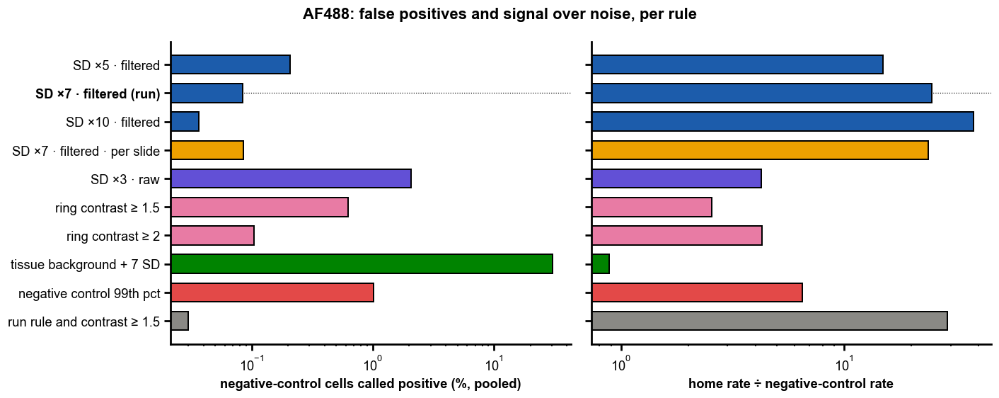

In [9]:
pooled = obs.groupby("rule")[["home +", "negative +", "negative cells"]].sum()
home_cells = sum(int((cells[n]["beside"] & (cells[n]["away"] < -GAP_UM) & (cells[n]["away"] >= -NEAR_UM)).sum())
                 for n in sections.index)
calls_table = pd.DataFrame({
    "family": pd.Series(FAMILY),
    "region % (median)": obs.groupby("rule")["region %"].median(),
    "crossed per mm (median)": obs.groupby("rule")["crossed per mm"].median(),
    "home per mm (median)": obs.groupby("rule")["home per mm"].median(),
    "share crossed (median)": obs.groupby("rule")["share crossed"].median(),
    "negative % (median)": obs.groupby("rule")["negative %"].median(),
    "negative % (pooled)": 100 * pooled["negative +"] / pooled["negative cells"],
    "home / negative (pooled)": (pooled["home +"] / home_cells) / (pooled["negative +"] / pooled["negative cells"]),
}).loc[RULE_NAMES]
display(calls_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
y = np.arange(len(RULE_NAMES))[::-1]
colours = [FAMILY_COLOURS[FAMILY[r]] for r in RULE_NAMES]
for ax, column, label in ((axes[0], "negative % (pooled)", "negative-control cells called positive (%, pooled)"),
                          (axes[1], "home / negative (pooled)", "home rate ÷ negative-control rate")):
    ax.barh(y, calls_table[column], color=colours, height=0.66, **EDGE)
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.axhline(y[RULE_NAMES.index(MAIN)], color="black", lw=0.8, ls=":", zorder=0)
axes[0].set_yticks(y, RULE_NAMES)
axes[0].get_yticklabels()[RULE_NAMES.index(MAIN)].set_fontweight("bold")
fig.suptitle(f"{CHANNEL}: false positives and signal over noise, per rule", fontweight="bold")
fig.tight_layout()
save(fig, "rules_false_positives")
plt.show()

## 5. Do the rules agree?

Left: on cells near the line (home or crossed), the **Jaccard index** of two rules' positives (cells both call ÷ cells either calls). Right: across sections, the **Spearman correlation** of crossed per mm. Two rules can call different cells yet rank the sections alike — and ranking is what a genotype comparison needs.

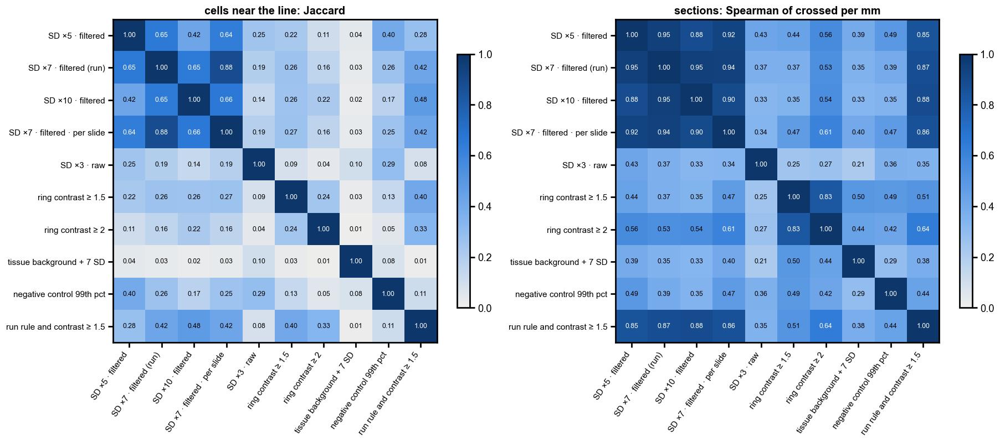

In [10]:
diag = np.diag(together).astype(float)
jaccard = together / np.maximum(diag[:, None] + diag[None, :] - together, 1)
spearman = obs.pivot(index="name", columns="rule", values="crossed per mm")[RULE_NAMES].corr(method="spearman").to_numpy()

agree_cmap = mpl.colors.LinearSegmentedColormap.from_list("agree", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(17, 7.4))
for ax, matrix, title in ((axes[0], jaccard, "cells near the line: Jaccard"),
                          (axes[1], spearman, "sections: Spearman of crossed per mm")):
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap=agree_cmap)
    ax.set_xticks(range(len(RULE_NAMES)), RULE_NAMES, rotation=55, ha="right", fontsize=10)
    ax.set_yticks(range(len(RULE_NAMES)), RULE_NAMES, fontsize=10)
    for i in range(len(RULE_NAMES)):
        for j in range(len(RULE_NAMES)):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if matrix[i, j] > 0.6 else "black")
    ax.set_title(title)
    for side in ax.spines.values():
        side.set_visible(True)
    fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
save(fig, "rules_agreement")
plt.show()

**Interactive: each rule against the run's rule, section by section.** Hover a dot for the section, its slide and QC; the grey line is equality. Sections far off the line are where the rules disagree — open them in the viewer. (Also written to `FIGURES/rules_vs_run.html`.)

In [11]:
wide = obs.pivot(index="name", columns="rule", values="crossed per mm")
long = wide.drop(columns=MAIN).melt(ignore_index=False, var_name="rule", value_name="other rule").join(wide[MAIN].rename("run rule"))
long = long.join(sections[["Genotype", "Experiment", "slide", "review status", "region by", "Quality"]]).reset_index()
long["short"] = long["name"].str.split("Asssembloid_").str[-1]
fig = px.scatter(long, x=long["run rule"] + 0.1, y=long["other rule"] + 0.1, color="Genotype", facet_col="rule",
                 facet_col_wrap=3, log_x=True, log_y=True, color_discrete_map=GENOTYPE_COLOURS, opacity=0.8,
                 hover_name="short", hover_data={"slide": True, "Experiment": True, "review status": True,
                                                 "region by": True, "Quality": True, "run rule": ":.1f", "other rule": ":.1f"},
                 labels={"x": "run rule: crossed per mm (+0.1)", "y": "other rule (+0.1)"},
                 height=1050, category_orders={"Genotype": GENOTYPES})
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
lo, hi = 0.1, float(np.nanmax(wide.to_numpy())) + 1
for k in range(len(RULE_NAMES) - 1):
    fig.add_shape(type="line", x0=lo, y0=lo, x1=hi, y1=hi, line=dict(color=GREY, width=1.5), row="all", col="all")
fig.update_xaxes(type="log")
fig.update_yaxes(type="log", matches=None, showticklabels=True)
plotly_style(fig)
fig.update_traces(marker=dict(size=6, line=dict(width=0.8, color="black")))
fig.write_html(FIGURES / "rules_vs_run.html", include_plotlyjs="cdn")
fig.show()

## 6. The genotype result under each rule

For every rule and outcome: a **mixed model** with slide as a random effect and experiment as a fixed one, on log(1 + y) for counts and logit for the share; the **fold change WT3 / GD1** (odds ratio for the share) with its 95 % CI. And the plain **slide-level** test: each slide's mean, Mann-Whitney between genotypes. Same conclusions = same direction and the same side of p = 0.05 under every rule with an acceptable false-positive rate.

In [12]:
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER_GENOTYPE}]"
LINK = {"crossed per mm": "log1p", "home per mm": "log1p", "share crossed": "logit", "region %": "log1p"}


def transform(y, link):
    y = pd.to_numeric(y, errors="coerce")
    return np.log((y + 0.01) / (1 - y + 0.01)) if link == "logit" else np.log1p(y)


def mixed(frame, column, extra=""):
    """Fold change OTHER_GENOTYPE / REFERENCE from a mixed model (slide random, experiment fixed)."""
    d = frame.copy()
    d["y"] = transform(d[column], LINK[column])
    d = d.dropna(subset=["y"])
    formula = f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)" + extra
    fit = smf.mixedlm(formula, d, groups=d["slide"]).fit(reml=True)
    lo, hi = fit.conf_int().loc[TERM]
    return {"fold": np.exp(fit.params[TERM]), "CI low": np.exp(lo), "CI high": np.exp(hi), "p": fit.pvalues[TERM],
            "sections": len(d), "slides": d["slide"].nunique(), "converged": fit.converged}


def slide_test(frame, column):
    """Slide means, Mann-Whitney OTHER_GENOTYPE vs REFERENCE."""
    s = frame.groupby("slide").agg({column: "mean", "Genotype": "first"})
    a = s.loc[s["Genotype"] == REFERENCE, column].dropna()
    b = s.loc[s["Genotype"] == OTHER_GENOTYPE, column].dropna()
    return {"slide ratio": b.median() / a.median() if a.median() else np.nan,
            "slide p": stats.mannwhitneyu(a, b).pvalue if len(a) and len(b) else np.nan}


effects = []
for rule in RULE_NAMES:
    frame = obs[obs["rule"] == rule]
    for outcome in LINK:
        try:
            row = mixed(frame, outcome)
        except Exception as exc:                       # a model that cannot be fitted says so
            row = {"fold": np.nan, "note": type(exc).__name__}
        effects.append({"rule": rule, "outcome": outcome, **row, **slide_test(frame, outcome)})
effects = pd.DataFrame(effects)
for outcome in LINK:
    print(f"--- {outcome}: {OTHER_GENOTYPE} / {REFERENCE}" + (" (odds ratio)" if LINK[outcome] == "logit" else ""))
    display(effects[effects["outcome"] == outcome].drop(columns="outcome").set_index("rule").round(3))

--- crossed per mm: WT3 / GD1


,fold,CI low,CI high,p,sections,slides,converged,slide ratio,slide p
rule,,,,,,,,,
SD ×5 · filtered,2.118,1.353,3.318,0.001,614,36,True,1.542,0.006
SD ×7 · filtered (run),2.697,1.657,4.390,0.000,614,36,True,1.977,0.001
SD ×10 · filtered,3.247,2.002,5.267,0.000,614,36,True,2.588,0.001
SD ×7 · filtered · per slide,2.615,1.619,4.224,0.000,614,36,True,2.015,0.001
SD ×3 · raw,1.839,1.124,3.008,0.015,614,36,True,1.448,0.031
ring contrast ≥ 1.5,0.991,0.577,1.703,0.974,614,36,True,1.083,0.975
ring contrast ≥ 2,1.649,1.044,2.603,0.032,614,36,True,1.939,0.375
tissue background + 7 SD,1.545,0.523,4.565,0.431,614,36,True,0.852,0.924
negative control 99th pct,1.249,0.887,1.757,0.202,614,36,True,1.106,0.680


--- home per mm: WT3 / GD1


,fold,CI low,CI high,p,sections,slides,converged,slide ratio,slide p
rule,,,,,,,,,
SD ×5 · filtered,3.115,2.161,4.491,0.000,614,36,True,1.735,0.001
SD ×7 · filtered (run),3.329,2.188,5.065,0.000,614,36,True,1.609,0.003
SD ×10 · filtered,3.403,2.135,5.426,0.000,614,36,True,1.474,0.005
SD ×7 · filtered · per slide,3.390,2.244,5.120,0.000,614,36,True,1.984,0.002
SD ×3 · raw,5.950,3.402,10.408,0.000,614,36,True,2.979,0.000
ring contrast ≥ 1.5,2.160,1.441,3.238,0.000,614,36,True,1.678,0.016
ring contrast ≥ 2,2.358,1.488,3.737,0.000,614,36,True,1.696,0.036
tissue background + 7 SD,3.016,1.338,6.800,0.008,614,36,True,1.231,0.342
negative control 99th pct,2.533,1.799,3.568,0.000,614,36,True,1.826,0.001


--- share crossed: WT3 / GD1 (odds ratio)


,fold,CI low,CI high,p,sections,slides,converged,slide ratio,slide p
rule,,,,,,,,,
SD ×5 · filtered,0.711,0.485,1.040,0.079,614,36,True,0.747,0.145
SD ×7 · filtered (run),0.860,0.576,1.286,0.463,610,36,True,0.883,0.657
SD ×10 · filtered,1.245,0.819,1.893,0.306,597,36,True,1.059,0.281
SD ×7 · filtered · per slide,0.800,0.536,1.193,0.274,611,36,True,0.864,0.428
SD ×3 · raw,0.314,0.182,0.543,0.000,612,36,True,0.534,0.000
ring contrast ≥ 1.5,0.429,0.275,0.670,0.000,611,36,True,0.587,0.001
ring contrast ≥ 2,0.787,0.450,1.377,0.401,523,36,True,0.656,0.326
tissue background + 7 SD,0.538,0.263,1.100,0.089,522,36,True,0.662,0.013
negative control 99th pct,0.507,0.387,0.665,0.000,610,36,True,0.601,0.000


--- region %: WT3 / GD1


,fold,CI low,CI high,p,sections,slides,converged,slide ratio,slide p
rule,,,,,,,,,
SD ×5 · filtered,1.436,1.223,1.685,0.000,614,36,True,1.814,0.002
SD ×7 · filtered (run),1.382,1.207,1.582,0.000,614,36,True,2.671,0.000
SD ×10 · filtered,1.282,1.155,1.423,0.000,614,36,True,3.222,0.000
SD ×7 · filtered · per slide,1.390,1.214,1.591,0.000,614,36,True,2.533,0.000
SD ×3 · raw,1.373,1.117,1.689,0.003,614,36,False,1.469,0.005
ring contrast ≥ 1.5,1.034,0.899,1.190,0.639,614,36,True,1.282,0.949
ring contrast ≥ 2,1.057,1.000,1.116,0.049,614,36,True,1.982,0.375
tissue background + 7 SD,1.051,0.614,1.798,0.857,614,36,True,0.754,0.590
negative control 99th pct,1.172,1.013,1.356,0.032,614,36,True,1.063,0.267


**The conclusion matrix** — one cell per rule and outcome: the fold change WT3 / GD1 from the mixed model, coloured blue where WT3 is higher and orange where GD1 is, stars for the mixed model's p. Read across a column: does every rule tell the same story?

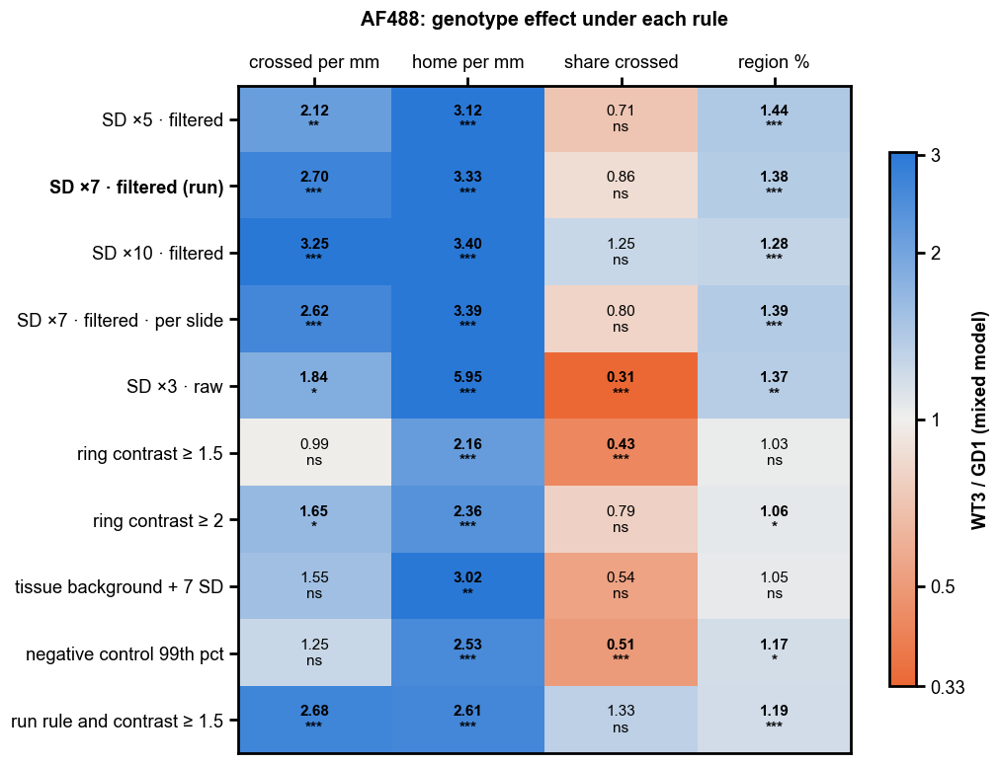

In [13]:
fold = effects.pivot(index="rule", columns="outcome", values="fold").loc[RULE_NAMES, list(LINK)]
pval = effects.pivot(index="rule", columns="outcome", values="p").loc[RULE_NAMES, list(LINK)]
diverge = mpl.colors.LinearSegmentedColormap.from_list("genotype", [GENOTYPE_COLOURS["GD1"], "#f0efec", GENOTYPE_COLOURS["WT3"]])
fig, ax = plt.subplots(figsize=(9.5, 7.2))
im = ax.imshow(np.log2(fold.to_numpy(float)), cmap=diverge, vmin=-1.6, vmax=1.6, aspect="auto")
for i in range(fold.shape[0]):
    for j in range(fold.shape[1]):
        f, p = fold.iat[i, j], pval.iat[i, j]
        ax.text(j, i, "n/a" if not np.isfinite(f) else f"{f:.2f}\n{stars(p)}", ha="center", va="center", fontsize=10,
                fontweight="bold" if np.isfinite(p) and p < 0.05 else "normal")
ax.set_xticks(range(fold.shape[1]), fold.columns)
ax.set_yticks(range(fold.shape[0]), fold.index)
ax.get_yticklabels()[RULE_NAMES.index(MAIN)].set_fontweight("bold")
ax.xaxis.tick_top()
for side in ax.spines.values():
    side.set_visible(True)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_ticks(np.log2([0.33, 0.5, 1, 2, 3]), labels=["0.33", "0.5", "1", "2", "3"])
cbar.set_label(f"{OTHER_GENOTYPE} / {REFERENCE} (mixed model)")
ax.set_title(f"{CHANNEL}: genotype effect under each rule", pad=40)
fig.tight_layout()
save(fig, "rules_conclusion_matrix")
plt.show()

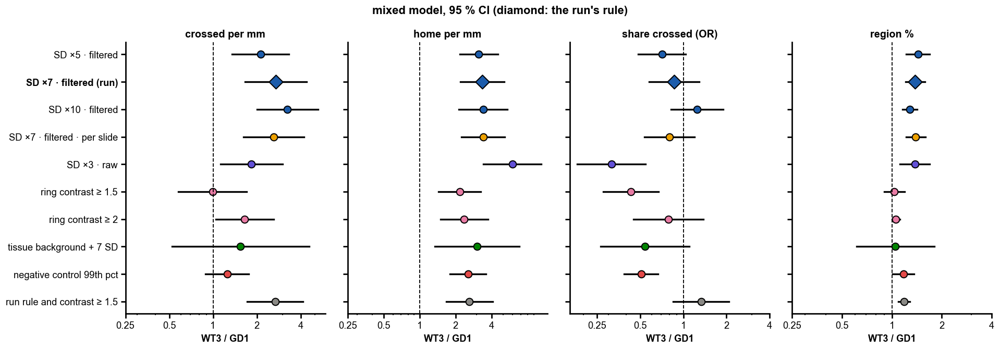

In [14]:
fig, axes = plt.subplots(1, len(LINK), figsize=(4.4 * len(LINK), 6.2), sharey=True)
y = np.arange(len(RULE_NAMES))[::-1]
for ax, outcome in zip(axes, LINK):
    e = effects[effects["outcome"] == outcome].set_index("rule").loc[RULE_NAMES]
    for k, rule in enumerate(RULE_NAMES):
        f, lo, hi = e.at[rule, "fold"], e.at[rule, "CI low"], e.at[rule, "CI high"]
        if not np.isfinite(f):
            continue
        ax.plot([lo, hi], [y[k], y[k]], color="black", lw=2.2, zorder=1)
        ax.scatter(f, y[k], s=150 if rule == MAIN else 80, marker="D" if rule == MAIN else "o",
                   color=FAMILY_COLOURS[FAMILY[rule]], zorder=2, **EDGE)
    ax.axvline(1, color="black", lw=1.2, ls="--")
    ax.set_xscale("log")
    ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_title(outcome + (" (OR)" if LINK[outcome] == "logit" else ""))
    ax.set_xlabel(f"{OTHER_GENOTYPE} / {REFERENCE}")
axes[0].set_yticks(y, RULE_NAMES)
axes[0].get_yticklabels()[RULE_NAMES.index(MAIN)].set_fontweight("bold")
fig.suptitle("mixed model, 95 % CI (diamond: the run's rule)", fontweight="bold")
fig.tight_layout()
save(fig, "rules_forest")
plt.show()

**Per experiment.** The same comparison inside each experiment (ratio of section medians WT3 / GD1, Mann-Whitney p): does a rule change which batches show the difference?

In [15]:
per_exp = {}
for rule in RULE_NAMES:
    frame = obs[obs["rule"] == rule]
    for e, part in frame.groupby("Experiment"):
        for outcome in ("crossed per mm", "home per mm", "share crossed"):
            a = part.loc[part["Genotype"] == REFERENCE, outcome].dropna()
            b = part.loc[part["Genotype"] == OTHER_GENOTYPE, outcome].dropna()
            if len(a) >= 3 and len(b) >= 3:
                ratio = b.median() / a.median() if a.median() else np.nan
                per_exp[(rule, f"{outcome} · exp {e}")] = f"{ratio:.2f} ({stars(stats.mannwhitneyu(a, b).pvalue)})"
display(pd.Series(per_exp).unstack().loc[RULE_NAMES])

,crossed per mm · exp 10,crossed per mm · exp 8,crossed per mm · exp 9,home per mm · exp 10,home per mm · exp 8,home per mm · exp 9,share crossed · exp 10,share crossed · exp 8,share crossed · exp 9
SD ×5 · filtered,1.71 (***),1.08 (ns),6.36 (***),2.82 (***),1.57 (***),10.63 (***),0.68 (***),0.70 (ns),0.72 (**)
SD ×7 · filtered (run),2.56 (***),1.22 (ns),10.42 (***),3.57 (***),1.52 (**),12.86 (***),0.90 (*),0.85 (ns),0.89 (ns)
SD ×10 · filtered,4.30 (***),1.46 (ns),16.85 (***),3.73 (***),1.42 (*),14.43 (***),1.33 (ns),1.26 (ns),1.33 (ns)
SD ×7 · filtered · per slide,2.44 (***),1.26 (ns),9.65 (***),3.18 (***),1.90 (***),12.34 (***),0.85 (**),0.90 (ns),0.83 (ns)
SD ×3 · raw,0.76 (ns),1.67 (ns),2.98 (***),5.91 (***),2.32 (***),54.33 (***),0.44 (***),0.81 (ns),0.21 (***)
ring contrast ≥ 1.5,1.53 (ns),1.02 (ns),1.76 (**),2.17 (***),1.49 (***),5.62 (***),0.80 (**),0.63 (***),0.44 (***)
ring contrast ≥ 2,2.09 (ns),1.29 (ns),3.90 (***),2.37 (***),1.64 (**),8.04 (***),0.95 (ns),0.89 (ns),0.64 (*)
tissue background + 7 SD,2.38 (ns),0.71 (ns),3.34 (***),4.42 (**),0.75 (ns),22.29 (***),0.55 (**),0.50 (**),0.73 (***)
negative control 99th pct,1.08 (ns),0.70 (***),2.39 (***),1.99 (***),1.45 (***),6.15 (***),0.65 (***),0.60 (***),0.49 (***)
run rule and contrast ≥ 1.5,2.59 (***),1.31 (ns),10.08 (***),2.66 (***),1.24 (**),8.95 (***),1.25 (ns),0.97 (ns),1.21 (*)


## 7. Sample bias and under-representation

### 7a. Which sections reached the run

From every scanned section (file list) → in the pre-screen → passed it (`Pass` = yes, not `Separated`) → accepted in the junction review and analysed (this run) → QC ok. A genotype or experiment that loses more sections at a step is under-represented, and the loss may not be random (e.g. GD1 junctions that are harder to find).

scanned  pre-screened  passed  in run  QC ok  kept of passed (%)
Genotype Experiment                                                                  
GD1      10            163.0         163.0   122.0   122.0    3.0               100.0
         8             159.0         159.0   122.0   111.0   34.0                91.0
         9             157.0         157.0   118.0   116.0   20.0                98.0
WT2      10            166.0           0.0     0.0     0.0    0.0                 NaN
         8             141.0           0.0     0.0     0.0    0.0                 NaN
         9             176.0           0.0     0.0     0.0    0.0                 NaN
WT3      10            183.0         183.0   123.0   100.0   61.0                81.0
         8             127.0         127.0    89.0    80.0    2.0                90.0
         9             182.0         182.0   134.0    85.0   50.0                63.0
all                   1454.0         971.0   708.0   614.0  170.0                87.0

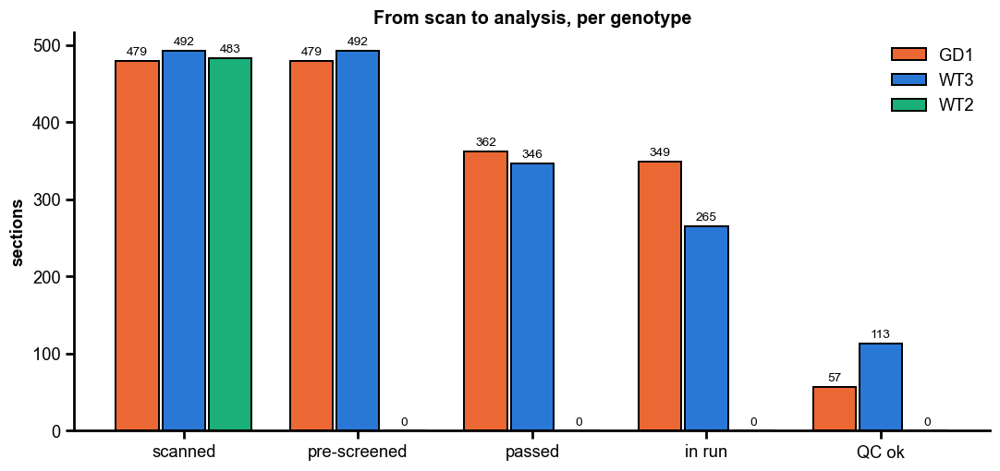

passed the pre-screen → in the run (rows: genotype; columns: 0 = left out, 1 = in):


in run,0,1
Genotype,,
GD1,28,334
WT3,86,260


Fisher exact p = 4.02e-10


In [16]:
scanned = design.set_index("name")
in_prescreen = scanned.index.isin(prescreen["name"])
passed = scanned.index.isin(prescreen.loc[(prescreen["Pass"] == "yes") & (prescreen["Shape"] != "Separated"), "name"])
in_run = scanned.index.isin(sections.index)
qc_ok = scanned.index.isin(sections.index[sections["QC ok"]])
funnel = pd.DataFrame({"scanned": 1, "pre-screened": in_prescreen, "passed": passed, "in run": in_run, "QC ok": qc_ok},
                      index=scanned.index).astype(int).join(scanned[["Genotype", "Experiment"]])
by = funnel.groupby(["Genotype", "Experiment"])[["scanned", "pre-screened", "passed", "in run", "QC ok"]].sum()
by.loc[("all", ""), :] = by.sum()
by["kept of passed (%)"] = (100 * by["in run"] / by["passed"].where(by["passed"] > 0)).round(0)
display(by)

steps = ["scanned", "pre-screened", "passed", "in run", "QC ok"]
genotypes_scanned = sorted(funnel["Genotype"].unique(), key=lambda g: (g not in GENOTYPES, g))
fig, ax = plt.subplots(figsize=(10, 4.8))
width = 0.8 / len(genotypes_scanned)
for k, g in enumerate(genotypes_scanned):
    values = funnel[funnel["Genotype"] == g][steps].sum()
    xs = np.arange(len(steps)) + (k - (len(genotypes_scanned) - 1) / 2) * width
    ax.bar(xs, values, width=width * 0.92, color=GENOTYPE_COLOURS.get(g, GREY), label=g, **EDGE)
    for x, v in zip(xs, values):
        ax.text(x, v + 4, str(int(v)), ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(steps)), steps)
ax.set_ylabel("sections")
ax.legend()
ax.set_title("From scan to analysis, per genotype")
fig.tight_layout()
save(fig, "bias_funnel")
plt.show()

# Is the loss from 'passed' to 'in run' the same for both genotypes?
table = pd.crosstab(funnel.loc[funnel["passed"] == 1, "Genotype"], funnel.loc[funnel["passed"] == 1, "in run"])
print("passed the pre-screen → in the run (rows: genotype; columns: 0 = left out, 1 = in):")
display(table)
if table.shape == (2, 2):
    print(f"Fisher exact p = {stats.fisher_exact(table.to_numpy())[1]:.3g}")

### 7b. Sections per slide

Sections on one slide are not independent. If a few slides contribute most sections, section-level statistics mostly describe those slides. The **effective number of slides** (1 / Σ share²) says how many equally sized slides the data are worth.

GD1: 19 slides, 349 sections, 4–29 per slide, effective number of slides 17.2
WT3: 17 slides, 265 sections, 4–24 per slide, effective number of slides 14.9


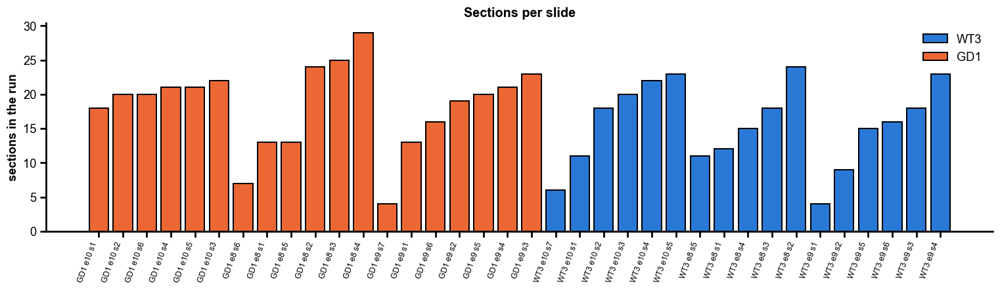

In [17]:
per_slide = sections.groupby("slide").agg(sections=("Genotype", "size"), Genotype=("Genotype", "first"),
                                          Experiment=("Experiment", "first")).sort_values(["Genotype", "Experiment", "sections"])
for g, part in per_slide.groupby("Genotype"):
    share = part["sections"] / part["sections"].sum()
    print(f"{g}: {len(part)} slides, {part['sections'].sum()} sections, {part['sections'].min()}–{part['sections'].max()} "
          f"per slide, effective number of slides {1 / (share ** 2).sum():.1f}")
fig, ax = plt.subplots(figsize=(14, 4.2))
xs = np.arange(len(per_slide))
ax.bar(xs, per_slide["sections"], color=[GENOTYPE_COLOURS[g] for g in per_slide["Genotype"]], width=0.8, **EDGE)
ax.set_xticks(xs, per_slide.index, rotation=70, ha="right", fontsize=8)
ax.set_ylabel("sections in the run")
ax.set_title("Sections per slide")
handles = [mpl.patches.Patch(facecolor=GENOTYPE_COLOURS[g], label=g, **EDGE) for g in GENOTYPES]
ax.legend(handles=handles)
fig.tight_layout()
save(fig, "bias_sections_per_slide")
plt.show()

### 7c. Do the genotypes differ in things that are not the biology?

Each covariate by genotype. Continuous ones: medians and the slide-level Mann-Whitney p (slide means). Yes/no ones: % of sections and Fisher's p (sections; read with care, sections on a slide are not independent). A covariate that differs **and** moves the outcome (7d) can fake or hide a genotype effect.

,GD1 median,WT3 median,p (slides),differs
junction line (µm),1132.409,992.457,0.410,ns
region area (mm²),0.369,0.331,0.342,ns
cell density in region (/mm²),18115.188,18433.244,0.776,ns
cells in section,37743.000,40083.000,0.113,ns
AF488 tissue background (a.u.),207.000,211.000,0.342,ns
AF488 spread in region (SD),23.686,24.006,0.704,ns
AF488+ in whole section (%),0.877,1.760,0.009,**
AF555+ in whole section (%),1.620,1.386,0.241,ns
hand-drawn region (% of sections),23.496,34.340,0.004,**
QC ok (% of sections),16.332,42.642,0.000,***


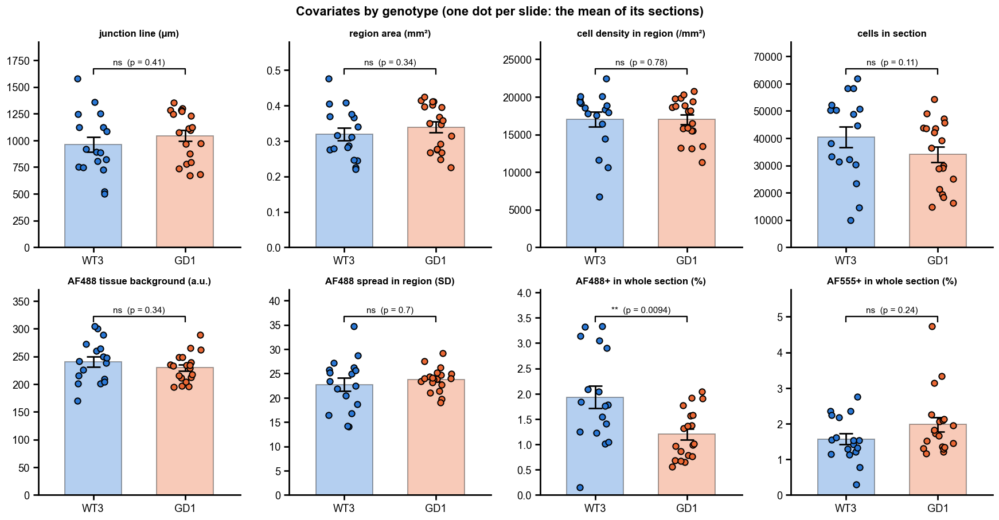

In [18]:
CONTINUOUS = {
    "junction length (um)": "junction line (µm)",
    "region area (mm2)": "region area (mm²)",
    "cells per mm2 of region": "cell density in region (/mm²)",
    "cells in section": "cells in section",
    f"{CHANNEL} background": f"{CHANNEL} tissue background (a.u.)",
    "filtered SD": f"{CHANNEL} spread in region (SD)",
    f"{CHANNEL} % positive in section": f"{CHANNEL}+ in whole section (%)",
    f"{OTHER} % positive in section": f"{OTHER}+ in whole section (%)",
}
sections["Quality good"] = sections["Quality"].eq("Good")
sections["Ripped (yes)"] = sections["Ripped"].eq("yes")
sections["Folded (yes)"] = sections["Folded"].eq("yes")
BINARY = ["hand-drawn region", "QC ok", "Quality good", "Ripped (yes)", "Folded (yes)", "home on region side"]

rows = {}
slides = sections.groupby("slide").agg({**{c: "mean" for c in CONTINUOUS}, "Genotype": "first"})
for column, label in CONTINUOUS.items():
    a = slides.loc[slides["Genotype"] == REFERENCE, column].dropna()
    b = slides.loc[slides["Genotype"] == OTHER_GENOTYPE, column].dropna()
    rows[label] = {f"{REFERENCE} median": sections.loc[sections["Genotype"] == REFERENCE, column].median(),
                   f"{OTHER_GENOTYPE} median": sections.loc[sections["Genotype"] == OTHER_GENOTYPE, column].median(),
                   "p (slides)": stats.mannwhitneyu(a, b).pvalue}
for column in BINARY:
    t = pd.crosstab(sections["Genotype"], sections[column].astype(bool)).reindex(columns=[False, True], fill_value=0)
    rows[f"{column} (% of sections)"] = {
        f"{REFERENCE} median": 100 * t.at[REFERENCE, True] / t.loc[REFERENCE].sum(),
        f"{OTHER_GENOTYPE} median": 100 * t.at[OTHER_GENOTYPE, True] / t.loc[OTHER_GENOTYPE].sum(),
        "p (slides)": stats.fisher_exact(t.loc[[REFERENCE, OTHER_GENOTYPE]].to_numpy())[1]}
covariates = pd.DataFrame(rows).T
covariates["differs"] = covariates["p (slides)"].map(stars)
display(covariates.round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for ax, (column, label) in zip(axes.flat, CONTINUOUS.items()):
    dots_and_bar(ax, slides.reset_index(), column, GENOTYPES, p=covariates.at[label, "p (slides)"])
    ax.set_title(label, fontsize=11)
fig.suptitle("Covariates by genotype (one dot per slide: the mean of its sections)", fontweight="bold")
fig.tight_layout()
save(fig, "bias_covariates")
plt.show()

### 7d. Do the covariates move the outcome, and does the genotype effect survive them?

Spearman correlation of each covariate with the run rule's outcomes (sections). Then the mixed model again with the covariates added: if the genotype fold barely moves, the covariates do not explain it.

In [19]:
sec = sections.join(main_obs[["crossed per mm", "home per mm", "share crossed", "region %"]])
corr = pd.DataFrame({o: {CONTINUOUS.get(c, c): stats.spearmanr(sec[c], sec[o], nan_policy="omit")[0]
                         for c in list(CONTINUOUS) + BINARY}
                     for o in ("crossed per mm", "home per mm", "share crossed", "region %")})
display(corr.round(2))

sec["log length"] = np.log(sec["junction length (um)"])
sec["log density"] = np.log(sec["cells per mm2 of region"])
sec["hand"] = sec["hand-drawn region"].astype(int)
sec["qc"] = sec["QC ok"].astype(int)
sec["good"] = sec["Quality good"].astype(int)
ADJUST = " + log_length + log_density + hand + qc + good"
adj = sec.rename(columns={"log length": "log_length", "log density": "log_density"}).reset_index()
rows = []
for outcome in ("crossed per mm", "home per mm", "share crossed"):
    for label, extra in (("experiment only", ""), ("+ length, density, hand-drawn, QC, quality", ADJUST)):
        try:
            rows.append({"outcome": outcome, "model": label, **mixed(adj, outcome, extra)})
        except Exception as exc:
            rows.append({"outcome": outcome, "model": label, "note": type(exc).__name__})
display(pd.DataFrame(rows).set_index(["outcome", "model"]).round(3))

,crossed per mm,home per mm,share crossed,region %
junction line (µm),-0.30,-0.41,0.12,-0.38
region area (mm²),-0.24,-0.35,0.11,-0.33
cell density in region (/mm²),0.20,-0.03,0.26,-0.03
cells in section,0.18,0.10,0.11,0.04
AF488 tissue background (a.u.),-0.13,-0.00,-0.14,-0.04
AF488 spread in region (SD),0.14,-0.19,0.37,0.04
AF488+ in whole section (%),0.48,0.77,-0.32,0.58
AF555+ in whole section (%),-0.02,0.12,-0.18,-0.01
hand-drawn region,-0.01,-0.05,0.07,0.02
QC ok,0.37,0.51,-0.19,0.39


fold  CI low  CI high      p  sections  slides  converged
outcome        model                                                                                                 
crossed per mm experiment only                             2.697   1.657    4.390  0.000       614      36       True
               + length, density, hand-drawn, QC, quality  2.298   1.498    3.526  0.000       614      36       True
home per mm    experiment only                             3.329   2.188    5.065  0.000       614      36       True
               + length, density, hand-drawn, QC, quality  2.624   1.914    3.596  0.000       614      36       True
share crossed  experiment only                             0.860   0.576    1.286  0.463       610      36       True
               + length, density, hand-drawn, QC, quality  0.907   0.616    1.337  0.622       610      36       True

**Within strata.** The review's QC status and who drew the region differ by genotype (7c) and QC ok goes with more positives. So the genotype comparison again inside each stratum alone (mixed model, run rule): the direction should hold in each.

In [20]:
rows = []
for column in ("QC ok", "hand-drawn region", "Quality good"):
    for value in (True, False):
        names = sections.index[sections[column] == value]
        frame = obs[(obs["rule"] == MAIN) & obs["name"].isin(names)]
        for outcome in ("crossed per mm", "home per mm", "share crossed"):
            try:
                rows.append({"stratum": f"{column} = {value}", "outcome": outcome, **mixed(frame, outcome)})
            except Exception as exc:
                rows.append({"stratum": f"{column} = {value}", "outcome": outcome, "note": type(exc).__name__})
strata = pd.DataFrame(rows)
display(strata.pivot(index="stratum", columns="outcome", values="fold").round(2)
        .join(strata.pivot(index="stratum", columns="outcome", values="p").round(4), rsuffix=" p")
        .join(strata.groupby("stratum")["sections"].max()))

,crossed per mm,home per mm,share crossed,crossed per mm p,home per mm p,share crossed p,sections
stratum,,,,,,,
QC ok = False,2.87,3.22,0.91,0.0002,0.000,0.6780,444
QC ok = True,1.78,2.10,0.86,0.0246,0.003,0.6328,170
Quality good = False,2.92,3.31,0.93,0.0000,0.000,0.6939,280
Quality good = True,2.68,3.75,0.79,0.0001,0.000,0.3380,334
hand-drawn region = False,2.48,4.02,0.66,0.0006,0.000,0.0493,441
hand-drawn region = True,3.06,3.39,1.01,0.0000,0.000,0.9675,173


**Interactive: covariate against outcome.** One dot per section, one panel per covariate; hover for the section. (Also `FIGURES/covariates_vs_outcome.html`.)

In [21]:
melted = sec.reset_index()[["name", "Genotype", "Experiment", "slide", "review status", "region by", "crossed per mm"]
                           + list(CONTINUOUS)].melt(
    id_vars=["name", "Genotype", "Experiment", "slide", "review status", "region by", "crossed per mm"],
    var_name="covariate", value_name="value")
melted["covariate"] = melted["covariate"].map(CONTINUOUS)
melted["short"] = melted["name"].str.split("Asssembloid_").str[-1]
fig = px.scatter(melted, x="value", y=melted["crossed per mm"] + 0.1, color="Genotype", facet_col="covariate",
                 facet_col_wrap=4, log_y=True, color_discrete_map=GENOTYPE_COLOURS, opacity=0.8, height=750,
                 hover_name="short", hover_data={"slide": True, "review status": True, "region by": True,
                                                 "crossed per mm": ":.1f", "value": ":.3g"},
                 labels={"y": "crossed per mm (+0.1)"}, category_orders={"Genotype": GENOTYPES})
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_xaxes(matches=None, showticklabels=True)
plotly_style(fig)
fig.update_traces(marker=dict(size=6, line=dict(width=0.8, color="black")))
fig.write_html(FIGURES / "covariates_vs_outcome.html", include_plotlyjs="cdn")
fig.show()

### 7e. Does one slide or one experiment carry the result?

The run rule's genotype fold (mixed model) again, leaving out one slide at a time and one experiment at a time. A result that flips or loses its CI when one unit goes is fragile.

leave one slide out (run rule):


,fold_min,fold_max,p_max,significant
outcome,,,,
crossed per mm,2.485,2.980,0.000,36/36
home per mm,3.094,3.732,0.000,36/36
share crossed,0.785,0.922,0.686,0/36


leave one experiment out:


fold  CI low  CI high      p  sections  slides
outcome        left out                                                      
crossed per mm (none)         2.697   1.657    4.390  0.000       614      36
               experiment 10  3.362   1.691    6.685  0.001       392      24
               experiment 8   3.640   2.040    6.493  0.000       423      25
               experiment 9   1.568   1.011    2.430  0.044       413      23
home per mm    (none)         3.329   2.188    5.065  0.000       614      36
               experiment 10  3.312   1.839    5.962  0.000       392      24
               experiment 8   4.970   3.035    8.138  0.000       423      25
               experiment 9   2.190   1.495    3.208  0.000       413      23
share crossed  (none)         0.860   0.576    1.286  0.463       610      36
               experiment 10  1.074   0.620    1.861  0.798       390      24
               experiment 8   0.774   0.526    1.138  0.192       420      25
               experiment 9   0.769   0.454    1.303  0.329       410      23

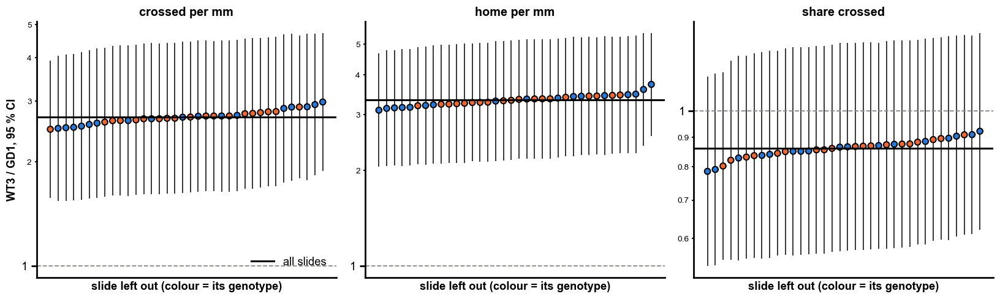

In [22]:
rows = []
frame = obs[obs["rule"] == MAIN]
for outcome in ("crossed per mm", "home per mm", "share crossed"):
    full = mixed(frame, outcome)
    rows.append({"outcome": outcome, "left out": "(none)", "kind": "all", **full})
    for slide in sorted(frame["slide"].unique()):
        try:
            rows.append({"outcome": outcome, "left out": slide, "kind": "slide",
                         **mixed(frame[frame["slide"] != slide], outcome)})
        except Exception:
            pass
    for e in sorted(frame["Experiment"].unique()):
        part = frame[frame["Experiment"] != e]
        try:
            rows.append({"outcome": outcome, "left out": f"experiment {e}", "kind": "experiment", **mixed(part, outcome)})
        except Exception:
            pass
loo = pd.DataFrame(rows)
summary_loo = loo[loo["kind"] == "slide"].groupby("outcome").agg(
    fold_min=("fold", "min"), fold_max=("fold", "max"), p_max=("p", "max"),
    significant=("p", lambda p: f"{int((p < 0.05).sum())}/{len(p)}"))
print("leave one slide out (run rule):")
display(summary_loo.round(3))
print("leave one experiment out:")
display(loo[loo["kind"] != "slide"].set_index(["outcome", "left out"])[["fold", "CI low", "CI high", "p", "sections", "slides"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=False)
for ax, outcome in zip(axes, ("crossed per mm", "home per mm", "share crossed")):
    part = loo[loo["outcome"] == outcome]
    s = part[part["kind"] == "slide"].sort_values("fold")
    ax.scatter(np.arange(len(s)), s["fold"], s=40, color=[GENOTYPE_COLOURS[x.split(" ")[0]] for x in s["left out"]], **EDGE, zorder=2)
    ax.vlines(np.arange(len(s)), s["CI low"], s["CI high"], color="black", lw=1, zorder=1)
    ax.axhline(part.loc[part["kind"] == "all", "fold"].iloc[0], color="black", lw=2, label="all slides")
    ax.axhline(1, color=GREY, lw=1.2, ls="--")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.tick_params(axis="y", which="minor", labelsize=9)
    ax.set_xticks([])
    ax.set_xlabel("slide left out (colour = its genotype)")
    ax.set_title(outcome)
axes[0].set_ylabel(f"{OTHER_GENOTYPE} / {REFERENCE}, 95 % CI")
axes[0].legend(loc="lower right")
fig.tight_layout()
save(fig, "bias_leave_one_slide_out")
plt.show()

## 8. Distance to the edge of the organoid

Do labelled cells that crossed travel **along the surface** of the other organoid, or through its middle? Each cell's distance to the tissue edge comes from the run (`Distance to the tissue edge`, µm; 0 = on the surface).

The raw distance depends on the shape of the section: a thin section has every cell near an edge. So each positive cell is also ranked among **all the cells of the same zone of the same section** — the **edge rank**: 0 = the cell nearest the surface, 1 = the deepest, **0.5 = where a cell taken at random would be**. A median edge rank below 0.5 means the positives lie nearer the surface than the tissue they are in.

Zones (on the line, as before): **crossed** — 2–300 µm past the line into the other organoid; **home** — 2–300 µm on the home side. Home is the control: if the labelled cells at home already sit near the surface, crossed cells near the surface say nothing new.

Change `EDGE_NEAR_UM` (what counts as "at the surface") or `EDGE_RULES` (the rules checked) here.

In [23]:
EDGE_NEAR_UM = 100.0     # a cell this close to the tissue edge is "at the surface"
EDGE_MIN = 3             # a zone's median needs at least this many positive cells
EDGE_RULES = [MAIN, "SD ×10 · filtered", "SD ×7 · filtered · per slide", "run rule and contrast ≥ 1.5"]
DEPTH_BINS = np.arange(0, NEAR_UM + 1, 50)    # µm past the line, for the surface-by-depth curve


def edge_rank(edges_of_zone, edges_of_positives):
    """Each positive's place among the zone's cells by distance to the edge: 0 nearest the surface, 1 deepest."""
    ordered = np.sort(edges_of_zone[np.isfinite(edges_of_zone)])
    if not len(ordered):
        return np.full(len(edges_of_positives), np.nan)
    return np.searchsorted(ordered, edges_of_positives, side="left") / len(ordered)


edge_rows, edge_cells = [], []
for name, s in sections.iterrows():
    c = cells[name]
    away, beside, edge = c["away"].to_numpy(), c["beside"].to_numpy(bool), c["edge"].to_numpy(float)
    zones = {"home": beside & (away < -GAP_UM) & (away >= -NEAR_UM),
             "crossed": beside & (away > GAP_UM) & (away <= NEAR_UM)}
    for rule in EDGE_RULES:
        positive = np.asarray(RULES[rule](c, s), bool)
        row = {"name": name, "rule": rule}
        for zone, inside in zones.items():
            hits = inside & positive
            ranks = edge_rank(edge[inside], edge[hits])
            enough = hits.sum() >= EDGE_MIN
            row[f"{zone} +"] = int(hits.sum())
            row[f"{zone} edge rank"] = np.median(ranks) if enough else np.nan
            row[f"{zone} + edge (um)"] = np.median(edge[hits]) if enough else np.nan
            row[f"{zone} all edge (um)"] = np.median(edge[inside]) if inside.any() else np.nan
            row[f"{zone} + at surface (%)"] = 100 * np.mean(edge[hits] <= EDGE_NEAR_UM) if enough else np.nan
            row[f"{zone} all at surface (%)"] = 100 * np.mean(edge[inside] <= EDGE_NEAR_UM) if inside.any() else np.nan
            if rule == MAIN:
                edge_cells.append(pd.DataFrame({"name": name, "zone": zone, "edge": edge[hits], "rank": ranks,
                                                "past": away[hits]}))
        edge_rows.append(row)
edges = pd.DataFrame(edge_rows).join(sections[["Genotype", "Experiment", "slide"]], on="name")
edge_cells = pd.concat(edge_cells, ignore_index=True).join(sections["Genotype"], on="name")
main_edges = edges[edges["rule"] == MAIN]
print(f"run rule: edge rank defined (≥ {EDGE_MIN} positives) for "
      f"{int(main_edges['home edge rank'].notna().sum())} sections at home, "
      f"{int(main_edges['crossed edge rank'].notna().sum())} past the line")

run rule: edge rank defined (≥ 3 positives) for 609 sections at home, 556 past the line


**Where do they sit?** Per genotype, the median over sections of: the positives' and all cells' distance to the edge, the % of each within `EDGE_NEAR_UM` of it, and the edge rank, with the Wilcoxon test of the edge rank against 0.5 (sections, and slide means). Then crossed against home in the same sections (paired).

In [24]:
def wilcoxon_p(values, centre=0.0):
    v = pd.Series(values).dropna() - centre
    v = v[v != 0]
    return stats.wilcoxon(v).pvalue if len(v) >= 5 else np.nan


rows = {}
for g in GENOTYPES:
    part = main_edges[main_edges["Genotype"] == g]
    slide_part = part.groupby("slide")[["home edge rank", "crossed edge rank"]].mean()
    for zone in ("home", "crossed"):
        rows[(g, zone)] = {
            "sections": int(part[f"{zone} edge rank"].notna().sum()),
            "positives: edge (µm)": part[f"{zone} + edge (um)"].median(),
            "all cells: edge (µm)": part[f"{zone} all edge (um)"].median(),
            f"positives ≤ {EDGE_NEAR_UM:g} µm (%)": part[f"{zone} + at surface (%)"].median(),
            f"all cells ≤ {EDGE_NEAR_UM:g} µm (%)": part[f"{zone} all at surface (%)"].median(),
            "edge rank (median)": part[f"{zone} edge rank"].median(),
            "rank vs 0.5: p (sections)": wilcoxon_p(part[f"{zone} edge rank"], 0.5),
            "rank vs 0.5: p (slides)": wilcoxon_p(slide_part[f"{zone} edge rank"], 0.5),
        }
    paired = part.dropna(subset=["home edge rank", "crossed edge rank"])
    diff = paired["crossed edge rank"] - paired["home edge rank"]
    rows[(g, "crossed − home")] = {"sections": len(paired), "edge rank (median)": diff.median(),
                                   "rank vs 0.5: p (sections)": wilcoxon_p(diff),
                                   "rank vs 0.5: p (slides)": wilcoxon_p(
                                       paired.assign(d=diff).groupby("slide")["d"].mean())}
edge_table = pd.DataFrame(rows).T
edge_table.index.names = ["genotype", "zone"]
display(edge_table.round(3))
print("(for 'crossed − home' the p columns test the paired difference against 0)")

sections  positives: edge (µm)  all cells: edge (µm)  positives ≤ 100 µm (%)  all cells ≤ 100 µm (%)  edge rank (median)  rank vs 0.5: p (sections)  rank vs 0.5: p (slides)
genotype zone                                                                                                                                                                                        
WT3      home               265.0               199.864               290.123                  18.720                   7.935               0.301                      0.000                    0.000
         crossed            245.0               196.945               293.002                  20.370                   7.021               0.317                      0.000                    0.000
         crossed − home     245.0                   NaN                   NaN                     NaN                     NaN              -0.004                      0.571                    0.818
GD1      home               344.0               242.502               320.386                  11.201                   7.420               0.353                      0.000                    0.000
         crossed            311.0               296.352               330.037                   4.167                   6.088               0.463                      0.000                    0.087
         crossed − home     308.0                   NaN                   NaN                     NaN                     NaN               0.029                      0.002                    0.096

(for 'crossed − home' the p columns test the paired difference against 0)


**Between genotypes**, under each low-noise rule: the mixed model (slide random, experiment fixed) on the edge rank of crossed and of home positives — the difference WT3 − GD1 in rank units (−0.1 = WT3's positives sit a tenth of the tissue nearer the surface).

In [25]:
def mixed_difference(frame, column):
    d = frame.dropna(subset=[column]).rename(columns={column: "y"})
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", d, groups=d["slide"]).fit(reml=True)
    lo, hi = fit.conf_int().loc[TERM]
    return {"WT3 − GD1": fit.params[TERM], "CI low": lo, "CI high": hi, "p": fit.pvalues[TERM],
            "sections": len(d), "slides": d["slide"].nunique()}


rows = []
for rule in EDGE_RULES:
    for zone in ("crossed", "home"):
        try:
            rows.append({"rule": rule, "zone": zone,
                         f"{REFERENCE} median": edges.loc[(edges["rule"] == rule) & (edges["Genotype"] == REFERENCE), f"{zone} edge rank"].median(),
                         f"{OTHER_GENOTYPE} median": edges.loc[(edges["rule"] == rule) & (edges["Genotype"] == OTHER_GENOTYPE), f"{zone} edge rank"].median(),
                         **mixed_difference(edges[edges["rule"] == rule], f"{zone} edge rank")})
        except Exception as exc:
            rows.append({"rule": rule, "zone": zone, "note": type(exc).__name__})
edge_effects = pd.DataFrame(rows).set_index(["zone", "rule"]).sort_index()
display(edge_effects.round(3))

GD1 median  WT3 median  WT3 − GD1  CI low  CI high      p  sections  slides
zone    rule                                                                                                     
crossed SD ×10 · filtered                  0.398       0.282     -0.092  -0.144   -0.039  0.001       418      36
        SD ×7 · filtered (run)             0.463       0.317     -0.095  -0.154   -0.036  0.002       556      36
        SD ×7 · filtered · per slide       0.469       0.319     -0.105  -0.161   -0.049  0.000       553      36
        run rule and contrast ≥ 1.5        0.473       0.335     -0.107  -0.157   -0.057  0.000       391      35
home    SD ×10 · filtered                  0.361       0.289     -0.076  -0.122   -0.031  0.001       596      36
        SD ×7 · filtered (run)             0.353       0.301     -0.057  -0.104   -0.010  0.017       609      36
        SD ×7 · filtered · per slide       0.361       0.304     -0.060  -0.105   -0.014  0.010       609      36
        run rule and contrast ≥ 1.5        0.381       0.334     -0.056  -0.108   -0.004  0.034       588      36

**Figures.** Left: the edge rank of each slide's positives at home and past the line, joined per slide (0.5 dashed: a random place in the tissue). Middle: every positive cell's distance to the edge, crossed (solid) against home (dashed), pooled per genotype, as cumulative curves — a curve further left means cells nearer the surface. Right: of the crossed positives, the % within `EDGE_NEAR_UM` of the surface by how far past the line they are, with the same for all cells past the line (grey) — do the ones that travel far stay on the surface?

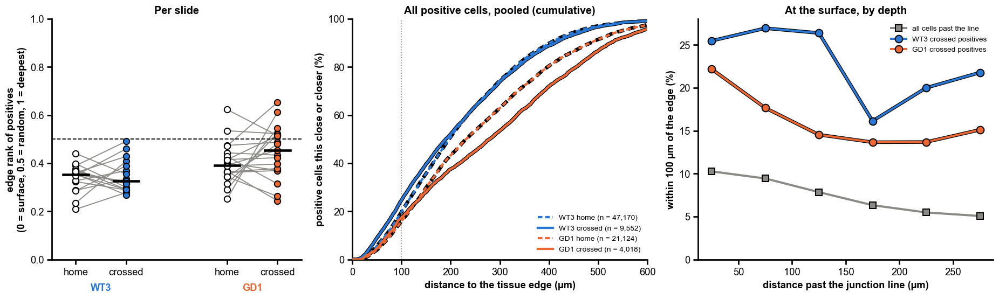

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1.3, 1.3]})

ax = axes[0]
slide_ranks = main_edges.groupby("slide").agg({"home edge rank": "mean", "crossed edge rank": "mean", "Genotype": "first"})
for k, g in enumerate(GENOTYPES):
    part = slide_ranks[slide_ranks["Genotype"] == g].dropna()
    x0, x1 = 3 * k, 3 * k + 1
    for _, r in part.iterrows():
        ax.plot([x0, x1], [r["home edge rank"], r["crossed edge rank"]], color=GREY, lw=1.2, zorder=1)
    for x, zone in ((x0, "home"), (x1, "crossed")):
        ax.scatter(np.full(len(part), x), part[f"{zone} edge rank"], s=55, zorder=3,
                   color=GENOTYPE_COLOURS[g] if zone == "crossed" else "white", **EDGE)
        ax.plot([x - 0.25, x + 0.25], [part[f"{zone} edge rank"].median()] * 2, color="black", lw=3, zorder=4)
ax.axhline(0.5, color="black", lw=1.2, ls="--")
ax.set_xticks([0, 1, 3, 4], ["home", "crossed", "home", "crossed"])
for k, g in enumerate(GENOTYPES):
    ax.text(3 * k + 0.5, -0.13, g, transform=ax.get_xaxis_transform(), ha="center", fontweight="bold",
            color=GENOTYPE_COLOURS[g])
ax.set_ylim(0, 1)
ax.set_ylabel("edge rank of positives\n(0 = surface, 0.5 = random, 1 = deepest)")
ax.set_title("Per slide")

ax = axes[1]
for g in GENOTYPES:
    for zone, style in (("home", (0, (2, 1.2))), ("crossed", "-")):
        e = np.sort(edge_cells.loc[(edge_cells["Genotype"] == g) & (edge_cells["zone"] == zone), "edge"].to_numpy())
        share = 100 * np.arange(1, len(e) + 1) / max(len(e), 1)
        ax.plot(e, share, color="black", lw=4.4, ls=style, zorder=2)
        ax.plot(e, share, color=GENOTYPE_COLOURS[g], lw=2.8, ls=style, zorder=3, label=f"{g} {zone} (n = {len(e):,})")
ax.axvline(EDGE_NEAR_UM, color=GREY, lw=1.2, ls=":")
ax.set_xlim(0, 600)
ax.set_ylim(0, 100)
ax.set_xlabel("distance to the tissue edge (µm)")
ax.set_ylabel("positive cells this close or closer (%)")
ax.set_title("All positive cells, pooled (cumulative)")
ax.legend(fontsize=9, loc="lower right")

ax = axes[2]
centres_depth = (DEPTH_BINS[:-1] + DEPTH_BINS[1:]) / 2
everyone = []
for name in sections.index:
    c = cells[name]
    past = c["beside"] & (c["away"] > GAP_UM) & (c["away"] <= NEAR_UM)
    everyone.append(pd.DataFrame({"past": c.loc[past, "away"].to_numpy(), "edge": c.loc[past, "edge"].to_numpy()}))
everyone = pd.concat(everyone)
depth_bin = np.digitize(everyone["past"], DEPTH_BINS) - 1
base = everyone.groupby(depth_bin)["edge"].apply(lambda e: 100 * np.mean(e <= EDGE_NEAR_UM)).reindex(range(len(centres_depth)))
ax.plot(centres_depth, base.to_numpy(), color=GREY, lw=2.6, marker="s", ms=8, label="all cells past the line")
crossed_cells = edge_cells[edge_cells["zone"] == "crossed"]
for g in GENOTYPES:
    part = crossed_cells[crossed_cells["Genotype"] == g]
    b = np.digitize(part["past"], DEPTH_BINS) - 1
    share = part.groupby(b)["edge"].apply(lambda e: 100 * np.mean(e <= EDGE_NEAR_UM)).reindex(range(len(centres_depth)))
    ax.plot(centres_depth, share.to_numpy(), color="black", lw=4.2, zorder=2)
    ax.plot(centres_depth, share.to_numpy(), color=GENOTYPE_COLOURS[g], lw=2.6, marker="o", ms=9, zorder=3,
            label=f"{g} crossed positives")
ax.set_xlabel("distance past the junction line (µm)")
ax.set_ylabel(f"within {EDGE_NEAR_UM:g} µm of the edge (%)")
ax.set_ylim(bottom=0)
ax.set_title("At the surface, by depth")
ax.legend(fontsize=9)
fig.tight_layout()
save(fig, "edge_distance")
plt.show()

**Interactive: every section.** Edge rank of the crossed positives against that of the home positives (run rule). Below the diagonal: the crossed cells sit nearer the surface than the labelled cells they came from. Hover for the section; the size of a dot is its number of crossed positives. (Also `FIGURES/edge_explorer.html`.)

In [27]:
view = main_edges.dropna(subset=["home edge rank", "crossed edge rank"]).join(
    sections[["review status", "region by", "Quality"]], on="name")
view["short"] = view["name"].str.split("Asssembloid_").str[-1]
fig = px.scatter(view, x="home edge rank", y="crossed edge rank", color="Genotype", size="crossed +", size_max=22,
                 color_discrete_map=GENOTYPE_COLOURS, opacity=0.8, hover_name="short",
                 hover_data={"slide": True, "review status": True, "region by": True, "Quality": True,
                             "home +": True, "crossed +": True, "crossed + edge (um)": ":.0f",
                             "home edge rank": ":.2f", "crossed edge rank": ":.2f"},
                 category_orders={"Genotype": GENOTYPES}, height=620, width=760)
fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line=dict(color=GREY, width=1.5, dash="dash"))
fig.add_hline(y=0.5, line=dict(color=GREY, width=1, dash="dot"))
fig.add_vline(x=0.5, line=dict(color=GREY, width=1, dash="dot"))
plotly_style(fig)
fig.update_traces(marker=dict(line=dict(width=1.2, color="black")))
fig.update_xaxes(range=[0, 1]); fig.update_yaxes(range=[0, 1])
fig.write_html(FIGURES / "edge_explorer.html", include_plotlyjs="cdn")
fig.show()

## 9. Figures for the slides

The run rule, **one dot per slide** (the mean of its sections), bar = mean ± SEM, p from the mixed model (all sections, slide random, experiment fixed). These are the numbers to present; the section-level versions are in the interactive plots.

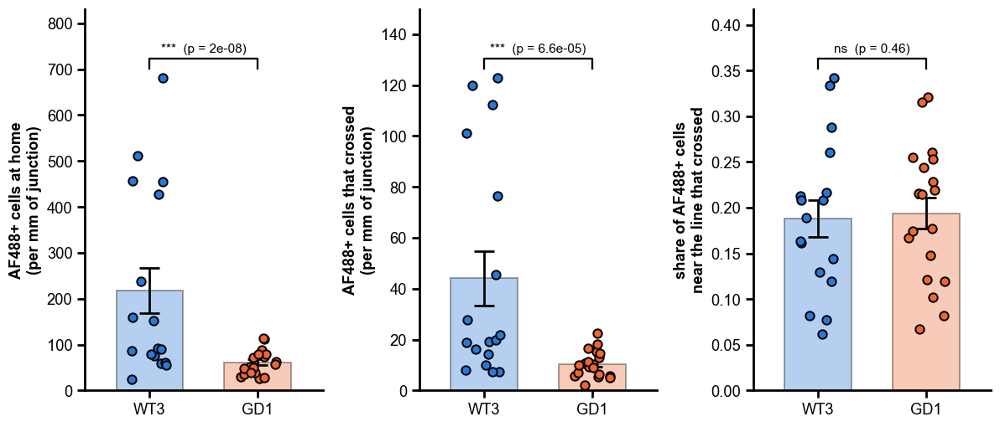

In [28]:
slide_means = obs[obs["rule"] == MAIN].groupby("slide").agg(
    {"crossed per mm": "mean", "home per mm": "mean", "share crossed": "mean", "region %": "mean",
     "Genotype": "first", "Experiment": "first"}).reset_index()
main_effects = effects[effects["rule"] == MAIN].set_index("outcome")
PANELS = {"home per mm": f"{CHANNEL}+ cells at home\n(per mm of junction)",
          "crossed per mm": f"{CHANNEL}+ cells that crossed\n(per mm of junction)",
          "share crossed": f"share of {CHANNEL}+ cells\nnear the line that crossed"}
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8))
for ax, (column, label) in zip(axes, PANELS.items()):
    dots_and_bar(ax, slide_means, column, GENOTYPES, p=main_effects.at[column, "p"])
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
fig.tight_layout()
save(fig, "main_slide_level")
plt.show()

**Profile across the junction.** % of cells positive (run rule) in 25 µm bins from 600 µm inside the home organoid (−) to 600 µm into the other one (+); mean over sections per genotype, band = ± SEM (the median is 0 past the line in most bins: most sections have few crossed cells, so the mean is what shows the tail). Expect a plateau at home, a drop at the line and a tail past it — the migrants.

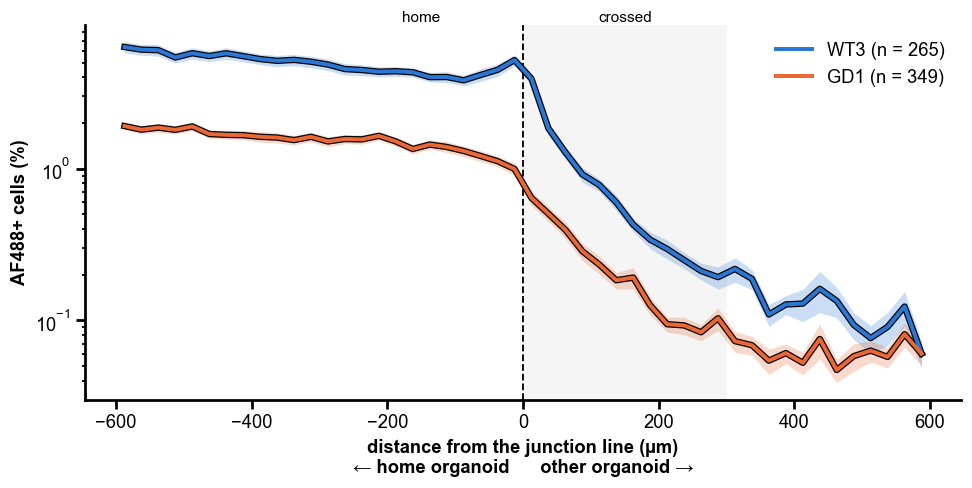

In [29]:
centres = (PROFILE_BINS[:-1] + PROFILE_BINS[1:]) / 2
profile = pd.DataFrame(profiles[MAIN], index=centres).T.join(sections["Genotype"])
fig, ax = plt.subplots(figsize=(9, 4.6))
for g in GENOTYPES:
    values = profile[profile["Genotype"] == g].drop(columns="Genotype")
    mean, sem = values.mean(), values.sem()
    ax.fill_between(centres, mean - sem, mean + sem, color=GENOTYPE_COLOURS[g], alpha=0.25, lw=0)
    ax.plot(centres, mean, color="black", lw=4.2, zorder=2)                            # black edge of the curve
    ax.plot(centres, mean, color=GENOTYPE_COLOURS[g], lw=2.6, zorder=3, label=f"{g} (n = {len(values)})")
ax.axvline(0, color="black", lw=1.2, ls="--")
ax.axvspan(GAP_UM, NEAR_UM, color=GREY, alpha=0.08, lw=0)
ax.text(NEAR_UM / 2, 1.0, "crossed", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=10)
ax.text(-NEAR_UM / 2, 1.0, "home", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=10)
ax.set_yscale("log")
ax.set_xlabel("distance from the junction line (µm)\n← home organoid      other organoid →")
ax.set_ylabel(f"{CHANNEL}+ cells (%)")
ax.legend()
fig.tight_layout()
save(fig, "main_profile")
plt.show()

**Per experiment, per slide.** The same three outcomes split by experiment: does every batch show it?

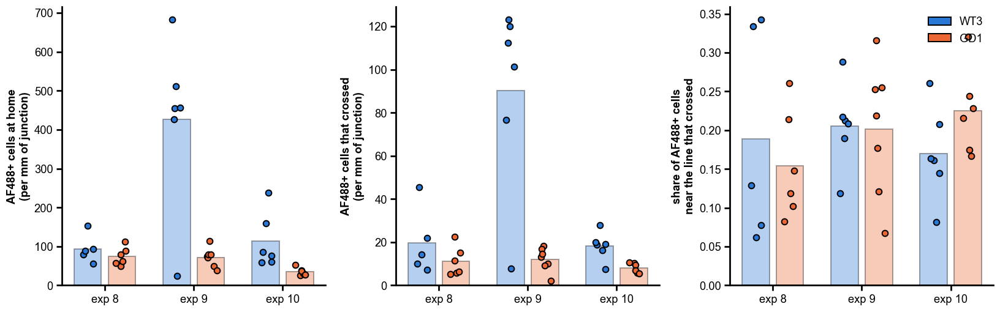

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
experiments = sorted(slide_means["Experiment"].unique(), key=int)
for ax, (column, label) in zip(axes, PANELS.items()):
    rng = np.random.default_rng(1)
    for i, e in enumerate(experiments):
        for k, g in enumerate(GENOTYPES):
            v = slide_means.loc[(slide_means["Experiment"] == e) & (slide_means["Genotype"] == g), column].dropna()
            x = i * 2.6 + k
            ax.bar(x, v.mean(), width=0.8, color=GENOTYPE_COLOURS[g], alpha=0.35, **EDGE)
            ax.scatter(x + rng.uniform(-0.18, 0.18, len(v)), v, s=40, color=GENOTYPE_COLOURS[g], zorder=3, **EDGE)
    ax.set_xticks([i * 2.6 + 0.5 for i in range(len(experiments))], [f"exp {e}" for e in experiments])
    ax.set_ylabel(label)
handles = [mpl.patches.Patch(facecolor=GENOTYPE_COLOURS[g], label=g, **EDGE) for g in GENOTYPES]
axes[-1].legend(handles=handles)
fig.tight_layout()
save(fig, "main_per_experiment")
plt.show()

## 10. Outliers

**Interactive: every section.** Home against crossed positives per mm (run rule), coloured by genotype, one symbol per experiment. Hover for the section, slide, QC, who drew the region and the pre-screen's Quality. Sections far above the cloud have many crossed cells for their home count — a wrong side, a fold, or real migration; check them in the viewer. (Also `FIGURES/sections_explorer.html`.)

In [31]:
explore = sec.reset_index()
explore["short"] = explore["name"].str.split("Asssembloid_").str[-1]
fig = px.scatter(explore, x=explore["home per mm"] + 0.1, y=explore["crossed per mm"] + 0.1, color="Genotype",
                 symbol="Experiment", log_x=True, log_y=True, color_discrete_map=GENOTYPE_COLOURS, opacity=0.85,
                 hover_name="short",
                 hover_data={"slide": True, "review status": True, "region by": True, "Quality": True,
                             "home per mm": ":.1f", "crossed per mm": ":.1f", "share crossed": ":.2f",
                             "junction length (um)": ":.0f", "home on region side": True},
                 labels={"x": f"{CHANNEL}+ at home per mm (+0.1)", "y": f"{CHANNEL}+ crossed per mm (+0.1)"},
                 category_orders={"Genotype": GENOTYPES}, height=620, width=900)
plotly_style(fig)
fig.write_html(FIGURES / "sections_explorer.html", include_plotlyjs="cdn")
fig.show()

**The most unusual sections**, by a robust z-score within their genotype (distance from the genotype's median in MADs, on log(1 + y)), so a section is flagged for being odd among its own kind.

In [32]:
def robust_z(values):
    v = np.log1p(values.astype(float))
    centre, spread = robust(v)
    return (v - centre) / spread if spread else v * np.nan


for column in ("crossed per mm", "home per mm", "share crossed"):
    sec[f"z {column}"] = sec.groupby("Genotype")[column].transform(robust_z)
sec["oddness"] = sec[[f"z {c}" for c in ("crossed per mm", "home per mm", "share crossed")]].abs().max(axis=1)
show = ["Genotype", "slide", "review status", "region by", "Quality", "crossed per mm", "home per mm",
        "share crossed", "oddness"]
display(sec.sort_values("oddness", ascending=False)[show].head(15).round(2))

,Genotype,slide,review status,region by,Quality,crossed per mm,home per mm,share crossed,oddness
name,,,,,,,,,
2025_09_26_Asssembloid_052-051_s19,GD1,GD1 e10 s1,check,junction finder,Good,11.35,0.00,1.00,5.27
2025_09_26_Asssembloid_047-046_s21,GD1,GD1 e9 s3,check,junction finder,Good,10.82,2.50,0.81,4.31
2025_09_26_Asssembloid_047-046_s23,GD1,GD1 e9 s3,check,junction finder,Good,6.59,1.65,0.80,4.24
2025_09_26_Asssembloid_053-052_s4,GD1,GD1 e10 s2,check,junction finder,Moderate,22.61,5.86,0.79,4.21
2025_09_26_Asssembloid_056-055_s14,GD1,GD1 e10 s5,check,junction finder,Good,17.01,5.67,0.75,3.96
2025_09_26_Asssembloid_047-046_s15,GD1,GD1 e9 s3,check,by hand,Moderate,10.17,3.63,0.74,3.89
2025_09_26_Asssembloid_038-037_s4,GD1,GD1 e8 s1,check,junction finder,Moderate,30.58,11.65,0.72,3.82
2025_09_26_Asssembloid_052-051_s21,GD1,GD1 e10 s1,check,junction finder,Good,0.00,0.00,NaN,3.72
2025_09_26_Asssembloid_021-020_s6,WT3,WT3 e8 s4,check,by hand,Good,10.61,3.75,0.74,3.59


## 11. Representative sections

Chosen by rule, not by eye: per genotype, among sections with QC ok, Quality Good and at least 2000 cells in the region, the ones **closest to their genotype's median**, at most one per slide, on log(1 + home per mm), log(1 + crossed per mm) and share crossed (distance in robust z units). Each is shown whole (the run's *positive cells* picture: region in white, junction line in yellow, positive cells ringed — cyan AF488, yellow AF555) and zoomed on the region. Change `N_EXAMPLES` or the filter to pick others; set `PICK` to a list of names to show your own choice.

,Genotype,slide,region by,home per mm,crossed per mm,share crossed
name,,,,,,
2025_09_26_Asssembloid_034-033_s2,WT3,WT3 e10 s4,junction finder,135.10,26.38,0.16
2025_09_26_Asssembloid_033-032_s2,WT3,WT3 e10 s3,junction finder,171.55,26.89,0.14
2025_09_26_Asssembloid_032-031_s23,WT3,WT3 e10 s2,junction finder,220.01,25.46,0.10
2025_09_26_Asssembloid_039-038_s1,GD1,GD1 e8 s2,junction finder,49.10,9.21,0.16
2025_09_26_Asssembloid_040-039_s23,GD1,GD1 e8 s3,by hand,32.06,9.38,0.23
2025_09_26_Asssembloid_041-040_s10,GD1,GD1 e8 s4,junction finder,94.45,7.60,0.07


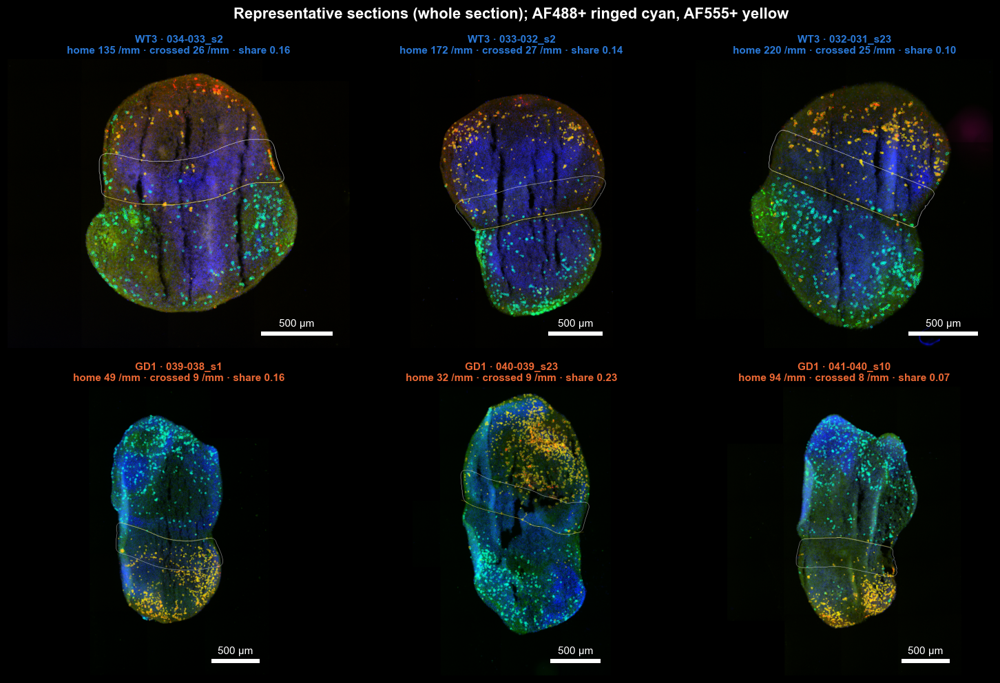

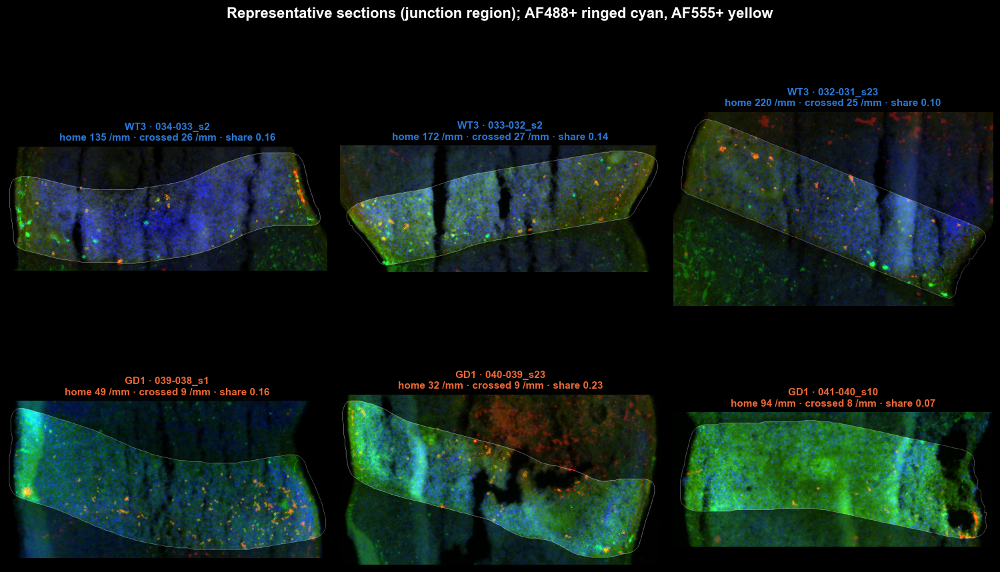

In [33]:
N_EXAMPLES = 3
PICK = None          # e.g. ["2025_09_26_Asssembloid_034-033_s13", ...] to override the automatic choice
HEADER_PX = 52       # rows of caption text at the top of the run's pictures, cropped away


def typical(frame):
    z = frame[[f"z {c}" for c in ("crossed per mm", "home per mm", "share crossed")]].fillna(0)
    return np.sqrt((z ** 2).sum(axis=1))


eligible = sec[sec["QC ok"] & sec["Quality good"] & (sec["cells in region"] >= 2000)]
if PICK:
    chosen = {g: [n for n in PICK if sections.at[n, "Genotype"] == g] for g in GENOTYPES}
else:
    chosen = {}
    for g in GENOTYPES:                                  # the most typical section of each slide, best slides first
        ranked = typical(eligible[eligible["Genotype"] == g]).sort_values()
        one_per_slide = ranked.groupby(sections.loc[ranked.index, "slide"]).head(1)
        chosen[g] = one_per_slide.index[:N_EXAMPLES].tolist()
display(sec.loc[[n for g in GENOTYPES for n in chosen[g]], ["Genotype", "slide", "region by", "home per mm",
                                                              "crossed per mm", "share crossed"]].round(2))


def picture(name, kind):
    """The run's picture of a section, caption cropped, black margins trimmed; µm per pixel for a scale bar."""
    path = RUN / "positive cells" / f"{name}.png" if kind == "whole" else \
        next((RUN / "region").glob(f"*/{name}.png"))
    image = Image.open(path).convert("RGB")
    image = image.crop((0, HEADER_PX, image.width, image.height))
    array = np.asarray(image)
    lit = np.argwhere(array.max(axis=2) > 25)
    (y0, x0), (y1, x1) = lit.min(axis=0), lit.max(axis=0)
    um_per_px = None
    if kind == "whole":
        info = json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))
        um_per_px = info["shape_yx"][1] * info["voxel_yx"][1] / Image.open(path).width
    return array[max(y0 - 10, 0):y1 + 10, max(x0 - 10, 0):x1 + 10], um_per_px


def scale_bar(ax, image, um_per_px, um=500):
    h, w = image.shape[:2]
    length = um / um_per_px
    x0, y0 = w - length - 0.05 * w, h - 0.05 * h
    ax.plot([x0, x0 + length], [y0, y0], color="white", lw=4, solid_capstyle="butt")
    ax.text(x0 + length / 2, y0 - 0.02 * h, f"{um} µm", color="white", ha="center", va="bottom", fontsize=10)


for kind in ("whole", "region"):
    fig, axes = plt.subplots(len(GENOTYPES), N_EXAMPLES, figsize=(4.6 * N_EXAMPLES, 4.6 * len(GENOTYPES)),
                             facecolor="black")
    for row, g in enumerate(GENOTYPES):
        for col in range(N_EXAMPLES):
            ax = axes[row, col]
            ax.set_facecolor("black")
            ax.set_xticks([]); ax.set_yticks([])
            for side in ax.spines.values():
                side.set_visible(False)
            if col >= len(chosen[g]):
                continue
            name = chosen[g][col]
            image, um_per_px = picture(name, kind)
            ax.imshow(image)
            if um_per_px:
                scale_bar(ax, image, um_per_px)
            r = sec.loc[name]
            ax.set_title(f"{g} · {name.split('Asssembloid_')[-1]}\nhome {r['home per mm']:.0f} /mm · crossed "
                         f"{r['crossed per mm']:.0f} /mm · share {r['share crossed']:.2f}",
                         color=GENOTYPE_COLOURS[g], fontsize=10, fontweight="bold")
    fig.suptitle(f"Representative sections ({'whole section' if kind == 'whole' else 'junction region'}); "
                 f"{CHANNEL}+ ringed cyan, {OTHER}+ yellow", color="white", fontweight="bold")
    fig.tight_layout()
    save(fig, f"representative_{kind}")
    plt.show()

**Figures written** (SVG for slides — the text stays editable; PNG at 300 dpi; HTML for the interactive ones):

In [34]:
for path in sorted(FIGURES.iterdir()):
    print(f"  {path.name}")

  bias_covariates.png
  bias_covariates.svg
  bias_funnel.png
  bias_funnel.svg
  bias_leave_one_slide_out.png
  bias_leave_one_slide_out.svg
  bias_sections_per_slide.png
  bias_sections_per_slide.svg
  covariates_vs_outcome.html
  edge_distance.png
  edge_distance.svg
  edge_explorer.html
  main_per_experiment.png
  main_per_experiment.svg
  main_profile.png
  main_profile.svg
  main_slide_level.png
  main_slide_level.svg
  representative_region.png
  representative_region.svg
  representative_whole.png
  representative_whole.svg
  rules_agreement.png
  rules_agreement.svg
  rules_conclusion_matrix.png
  rules_conclusion_matrix.svg
  rules_false_positives.png
  rules_false_positives.svg
  rules_forest.png
  rules_forest.svg
  rules_vs_run.html
  sections_explorer.html


## What it showed (29 October 2026: 614 reviewed sections, 36 slides — 17 WT3, 19 GD1 — experiments 8–10; 14.2 million cells within 650 µm of the lines)

**The recomputation is exact.** The run's rule recomputed here calls the same cells as the run (0 differences) and the same region counts as `counts.xlsx` in all 614 sections. In 12 sections (9 WT3, 3 GD1) AF488's home is on the region's side: there the run's "positive in the region" counts cells at home, not migrants. The line-based outcomes here orient each section by its own home, so they are not affected.

**The rules, on false positives.** Pooled over all sections, the run's rule calls 0.08 % of negative-control cells positive, and AF488-positive cells are 25× more frequent at home than in the control. SD ×10 and *run rule and contrast ≥ 1.5* are cleaner still (0.04 %, 0.03 %). The SD bar pooled per slide behaves like the per-section one (0.09 %, Jaccard and ranking close to the run's). The noisy rules call 0.6–2 % of the control: raw + 3 SD, ring contrast ≥ 1.5 and the negative control's 99th percentile, with signal over noise of only 2.5–6.5×. **Tissue background + 7 SD is not usable**: it calls 30 % of the control in some sections (signal over noise 0.9×).

**Same conclusions?** Under every rule with an acceptable false-positive rate (the SD ×5/7/10 rules, per slide, and *run rule and contrast*), the answer is the one from 22 October:
- **AF488-positive cells at home: more in WT3.** 2.6–3.4× under those rules (mixed model p < 0.001), and 2.2–6.0× under **all 10 rules** (every p < 0.01).
- **Crossed cells per mm: more in WT3.** 2.1–3.2× (p ≤ 0.001). Under the noisy rules this result disappears or shrinks: ring contrast ≥ 1.5 gives 0.99×, the negative control's 99th percentile 1.25× (ns), tissue background 1.5× (ns), raw + 3 SD 1.8× (p 0.015).
- **Share of labelled cells that crossed: no difference.** Odds ratio 0.80–1.33, all p > 0.2 (run rule 0.86, p 0.46).
- The noisy rules (raw + 3 SD, ring contrast ≥ 1.5, negative-control 99th percentile) give WT3 a *lower* share (OR 0.31–0.51, p < 0.001). This is the dilution seen on 22 October: false positives add the same number of cells on both sides of the line, which lowers the share most where there are more true labelled cells at home (WT3). It is not evidence of less migration.

**By experiment.** Home per mm is higher in WT3 in all three experiments under every SD rule. Crossed per mm differs in experiments 9 (10×) and 10 (2.6×) but **not in experiment 8 under any rule** (1.1–1.7×, ns). Leaving out experiment 9 drops the crossed fold from 2.7× to 1.6× (p 0.044).

**Sample bias.**
- **WT2 is missing entirely.** Its 483 scanned sections were never pre-screened, so the study is WT3 against GD1 only.
- **WT3 lost more sections between the pre-screen and the run**: 86 of 346 passing WT3 sections are not in the run, against 28 of 362 GD1 (Fisher p 4e-10). Worst is WT3 experiment 9, with only 85 of 134 kept (63 %). These are sections not accepted in the junction review; why they were left out should be checked, since it may not be random.
- **QC status differs strongly by genotype**: "ok" for 43 % of WT3 sections against 16 % of GD1 (GD1 experiment 10: 3 of 122). Hand-drawn regions (34 % vs 23 %) and Folded (32 % vs 23 %) are also more common in WT3.
- QC ok goes with more positives (Spearman 0.51 with home per mm), partly because the finder's "labelled cells on both sides" flag is what makes a junction "check".
- The physical covariates do not differ (slide level, all p > 0.1): junction length, region area, cell density, cells per section, AF488 background, AF488 spread. AF488+ in the whole section does differ: **1.8 % vs 0.9 % (p 0.009)**. That is the labelling difference again, not a covariate to adjust away.

**Does the bias explain the result? No.**
- Adjusting the mixed model for junction length, density, hand-drawn region, QC and Quality moves the folds only a little: crossed 2.7 → 2.3×, home 3.3 → 2.6×, share 0.86 → 0.91 (ns).
- Within each stratum alone (QC ok or check, hand-drawn or not, Quality good or not), WT3 is higher at home (2.1–4.0×) and in crossed cells (1.8–3.1×), and the share does not differ, except a borderline OR 0.66 (p 0.049) among finder-drawn regions.
- Leaving out any one slide never changes a conclusion: crossed 2.5–3.0× and home 3.1–3.7×, significant in 36/36; share 0.79–0.92, significant in 0/36.

**Distance to the edge of the organoid (section 8).**
- **Labelled cells lie nearer the surface than the tissue around them, in both genotypes.** Median edge rank 0.30–0.35 at home (0.5 = random place; p < 0.001 against 0.5, sections and slides). Within 100 µm of the edge: 19 % of WT3 home positives and 11 % of GD1's, against 7–8 % of all cells.
- **WT3's crossed cells stay as near the surface as its home cells**: rank 0.32 vs 0.30, no paired difference (p 0.57). Within 100 µm of the edge: 20 % against 7 % of all cells past the line, at every depth up to 300 µm.
- **GD1's crossed cells sit deeper than its home cells**: rank 0.46 vs 0.35. Paired p 0.002 on sections, 0.096 on slides. Only 4 % are within 100 µm of the edge, against 6 % of all cells. In GD1 the crossed cells are placed almost at random with respect to the surface.
- **Between genotypes**, WT3's crossed positives are nearer the surface than GD1's by 0.10 in rank. The mixed model gives p 0.002 with the run's rule, and −0.09 to −0.11 (p ≤ 0.002) under all four low-noise rules checked. At home the difference is smaller: −0.06 to −0.08, p 0.001–0.03.
- **Read with care.** This is distance to the nearest tissue edge in a 2D section, and part of the "edge" is the cut face or a tear. The surface route in WT3 is consistent with the 22 October finding (crossed cells nearer the edge in 213 of 288 WT3 sections, not in GD1). It suggests a different route, not a different rate: the share crossed is still equal.

**Decision.**
- Keep the run's rule (SD ×7 on the filtered mean, bar per section).
- Report: WT3 has ~3× more AF488-positive cells near the junction (home and crossed), robust to the rule, covariates, strata and any single slide. A labelled cell is **not** more likely to have crossed in WT3 (share crossed equal).
- Do not use ring contrast ≥ 1.5, raw + 3 SD, the negative-control percentile or the tissue background as positivity rules: their false positives reverse the share result.
- To do: find out why 86 passing WT3 sections (experiment 9 especially) were not accepted in the review; and pre-screen WT2 if it belongs in the comparison.

**Representative sections** (closest to their genotype's median, QC ok, Quality Good): one per slide — WT3 034-033_s2, 033-032_s2, 032-031_s23; GD1 039-038_s1, 040-039_s23, 041-040_s10. The WT3 picks all come from experiment 10 and the GD1 picks from experiment 8 (where the most typical, QC-ok sections are); set `PICK` to show others.